In [1]:
# Parte 1 - Preparação do ambiente

import sys
import torch
import torchvision
import cv2
import pandas as pd

print("Versão do Python:", sys.version)
print("Versão do PyTorch:", torch.__version__)
print("Versão do Torchvision:", torchvision.__version__)
print("Versão do OpenCV:", cv2.__version__)

# Verifica se existe uma GPU CUDA disponível
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Dispositivo: GPU")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("Dispositivo: CPU")

Versão do Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Versão do PyTorch: 2.14.1+cpu
Versão do Torchvision: 0.29.1+cpu
Versão do OpenCV: 5.0.0
Dispositivo: CPU


In [3]:
# Parte 1 - Conhecendo a divisão oficial dos dados

from pathlib import Path
import pandas as pd

# Localiza o arquivo splits.csv na pasta do projeto
splits_path = Path("splits.csv").resolve()

print("Arquivo encontrado:", splits_path.exists())
print("Localização:", splits_path)

if splits_path.exists():
    splits = pd.read_csv(splits_path)

    print("\nQuantidade de registros:", len(splits))

    print("\nPrimeiras cinco linhas:")
    display(splits.head())

    print("\nDistribuição dos conjuntos:")
    print(splits["split"].value_counts())

    print("\nImagens duplicadas:")
    print(splits["photo_name"].duplicated().sum())

Arquivo encontrado: True
Localização: C:\Users\Arnóbio\OneDrive\Desktop\CESAR SCHOOL\Visão Computacional\Pratica_2_Hidrometros\vc-20262-p2\splits.csv

Quantidade de registros: 1243

Primeiras cinco linhas:


,photo_name,split
0,id_1000_value_176_881.jpg,train
1,id_1001_value_1113_124.jpg,train
2,id_1002_value_105_174.jpg,train
3,id_1003_value_209_317.jpg,train
4,id_1004_value_37_176.jpg,train



Distribuição dos conjuntos:
split
train    870
test     187
val      186
Name: count, dtype: int64

Imagens duplicadas:
0


In [3]:
# Parte 1 - Verificação da integridade do dataset

from pathlib import Path
import zipfile

# Localização do arquivo baixado
zip_path = Path("data/yandextoloka-water-meters-dataset.zip")

# Verifica se o arquivo existe
print("Arquivo encontrado:", zip_path.exists())

if zip_path.exists():

    # Mostra o tamanho do arquivo em MB
    tamanho_mb = zip_path.stat().st_size / (1024 ** 2)
    print(f"Tamanho do arquivo: {tamanho_mb:.2f} MB")

    # Verifica a integridade do ZIP
    with zipfile.ZipFile(zip_path, "r") as arquivo:
        arquivo_corrompido = arquivo.testzip()

        print("Quantidade de arquivos no ZIP:", len(arquivo.namelist()))

        if arquivo_corrompido is None:
            print("Integridade: OK")
        else:
            print("Arquivo com problema:", arquivo_corrompido)

Arquivo encontrado: True
Tamanho do arquivo: 982.21 MB
Quantidade de arquivos no ZIP: 3733
Integridade: OK


In [4]:
# Parte 1 - Exploração da estrutura do dataset

from pathlib import Path
from collections import Counter
import zipfile

zip_path = Path("data/yandextoloka-water-meters-dataset.zip")

with zipfile.ZipFile(zip_path, "r") as arquivo:

    nomes = arquivo.namelist()

    # Identifica as pastas principais
    pastas = sorted({
        nome.split("/")[0]
        for nome in nomes
        if "/" in nome
    })

    print("PASTAS PRINCIPAIS:")
    for pasta in pastas:
        print("-", pasta)

    # Conta os tipos de arquivos
    extensoes = Counter(
        Path(nome).suffix.lower()
        for nome in nomes
        if not nome.endswith("/")
    )

    print("\nTIPOS DE ARQUIVOS:")
    for extensao, quantidade in extensoes.most_common():
        print(extensao or "(sem extensão)", ":", quantidade)

    # Localiza arquivos CSV
    arquivos_csv = [
        nome for nome in nomes
        if nome.lower().endswith(".csv")
    ]

    print("\nARQUIVOS CSV:")
    for nome in arquivos_csv:
        print("-", nome)

PASTAS PRINCIPAIS:
- WaterMeters

TIPOS DE ARQUIVOS:
.jpg : 3732
.csv : 1

ARQUIVOS CSV:
- WaterMeters/data.csv


In [5]:
# Parte 1 - Identificação das subpastas do WaterMeters

from collections import Counter
import zipfile

zip_path = "data/yandextoloka-water-meters-dataset.zip"

with zipfile.ZipFile(zip_path, "r") as arquivo:

    # Obtém os nomes dos arquivos dentro do ZIP
    nomes = arquivo.namelist()

    # Conta quantos arquivos existem em cada pasta
    contagem_pastas = Counter()

    for nome in nomes:

        # Ignora entradas que representam diretórios
        if nome.endswith("/"):
            continue

        # Identifica a pasta que contém o arquivo
        partes = nome.split("/")

        pasta = "/".join(partes[:-1])

        contagem_pastas[pasta] += 1

    print("DISTRIBUIÇÃO DOS ARQUIVOS POR PASTA:\n")

    for pasta, quantidade in sorted(contagem_pastas.items()):
        print(f"{pasta}: {quantidade} arquivos")

DISTRIBUIÇÃO DOS ARQUIVOS POR PASTA:

WaterMeters: 1 arquivos
WaterMeters/collage: 1244 arquivos
WaterMeters/images: 1244 arquivos
WaterMeters/masks: 1244 arquivos


In [6]:
# Parte 1 - Extração do dataset WaterMeters

from pathlib import Path
import zipfile

# Arquivo ZIP baixado do Kaggle
zip_path = Path("data/yandextoloka-water-meters-dataset.zip")

# Pasta onde os arquivos serão extraídos
extract_dir = Path("data")

# Extrai os arquivos mantendo a estrutura original
with zipfile.ZipFile(zip_path, "r") as arquivo:
    arquivo.extractall(extract_dir)

print("Extração concluída!")

# Verifica se as pastas foram criadas
watermeters_dir = extract_dir / "WaterMeters"

print("Pasta WaterMeters encontrada:", watermeters_dir.exists())
print("Arquivo data.csv encontrado:", (watermeters_dir / "data.csv").exists())

Extração concluída!
Pasta WaterMeters encontrada: True
Arquivo data.csv encontrado: True


In [2]:
# Parte 1 - Exploração das anotações do WaterMeters

import pandas as pd
from pathlib import Path

# Caminho do arquivo de anotações
csv_path = Path("data/WaterMeters/data.csv")

# Carrega o CSV em uma tabela do Pandas
df = pd.read_csv(csv_path)

# Mostra a quantidade de linhas e colunas
print("Dimensões do dataset:", df.shape)

# Mostra os nomes das colunas
print("\nNOMES DAS COLUNAS:")
print(df.columns.tolist())

# Mostra as primeiras cinco linhas
print("\nPRIMEIRAS CINCO LINHAS:")
display(df.head())

# Mostra os tipos de dados e valores ausentes
print("\nINFORMAÇÕES GERAIS:")
df.info()

print("\nVALORES AUSENTES POR COLUNA:")
print(df.isna().sum())

Dimensões do dataset: (1244, 3)

NOMES DAS COLUNAS:
['photo_name', 'value', 'location']

PRIMEIRAS CINCO LINHAS:


,photo_name,value,location
0,id_53_value_595_825.jpg,595.825,"{'type': 'polygon', 'data': [{'x': 0.30788, 'y..."
1,id_553_value_65_475.jpg,65.475,"{'type': 'polygon', 'data': [{'x': 0.26133, 'y..."
2,id_407_value_21_86.jpg,21.860,"{'type': 'polygon', 'data': [{'x': 0.27545, 'y..."
3,id_252_value_313_322.jpg,313.322,"{'type': 'polygon', 'data': [{'x': 0.21967, 'y..."
4,id_851_value_305_162.jpg,305.162,"{'type': 'polygon', 'data': [{'x': 0.06983, 'y..."



INFORMAÇÕES GERAIS:
<class 'pandas.DataFrame'>
RangeIndex: 1244 entries, 0 to 1243
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   photo_name  1244 non-null   str    
 1   value       1244 non-null   float64
 2   location    1244 non-null   str    
dtypes: float64(1), str(2)
memory usage: 29.3 KB

VALORES AUSENTES POR COLUNA:
photo_name    0
value         0
location      0
dtype: int64


In [8]:
# Parte 1 - Verificação da qualidade das anotações

print("VALORES AUSENTES POR COLUNA:")
print(df.isna().sum())

print("\nTIPOS DE DADOS:")
print(df.dtypes)

print("\nTOTAL DE NOMES DE IMAGENS DISTINTOS:")
print(df["photo_name"].nunique())

print("\nTOTAL DE REGISTROS:")
print(len(df))

VALORES AUSENTES POR COLUNA:
photo_name    0
value         0
location      0
dtype: int64

TIPOS DE DADOS:
photo_name        str
value         float64
location          str
dtype: object

TOTAL DE NOMES DE IMAGENS DISTINTOS:
1244

TOTAL DE REGISTROS:
1244


In [10]:
# Parte 1 - Comparação entre os rótulos do CSV e os nomes dos arquivos

import re
import pandas as pd

# Extrai a parte inteira e a parte decimal do nome da imagem
padrao = r"id_\d+_value_(\d+)_(\d+)\.jpg"

partes = df["photo_name"].str.extract(padrao)

partes.columns = ["inteiro", "decimal"]

# Verifica quantos nomes seguem o formato esperado
print("Nomes reconhecidos:", partes.dropna().shape[0])
print("Nomes fora do padrão:", partes.isna().any(axis=1).sum())

# Reconstrói a leitura registrada no nome do arquivo
valor_nome = pd.to_numeric(
    partes["inteiro"] + "." + partes["decimal"],
    errors="coerce"
)

# Compara com o valor registrado no CSV
diferenca = (valor_nome - df["value"]).abs()

divergencias = diferenca > 1e-6

print("\nQuantidade de divergências:", divergencias.sum())

print("\nEXEMPLOS DE COMPARAÇÃO:")

comparacao = pd.DataFrame({
    "photo_name": df["photo_name"],
    "valor_csv": df["value"],
    "valor_nome": valor_nome,
    "divergencia": divergencias
})

display(comparacao.head(10))

print("\nREGISTROS DIVERGENTES:")
display(comparacao[divergencias].head(10))

Nomes reconhecidos: 1244
Nomes fora do padrão: 0

Quantidade de divergências: 0

EXEMPLOS DE COMPARAÇÃO:


,photo_name,valor_csv,valor_nome,divergencia
0,id_53_value_595_825.jpg,595.825,595.825,False
1,id_553_value_65_475.jpg,65.475,65.475,False
2,id_407_value_21_86.jpg,21.860,21.860,False
3,id_252_value_313_322.jpg,313.322,313.322,False
4,id_851_value_305_162.jpg,305.162,305.162,False
5,id_398_value_8_898.jpg,8.898,8.898,False
6,id_1204_value_78_677.jpg,78.677,78.677,False
7,id_83_value_1336_114.jpg,1336.114,1336.114,False
8,id_1061_value_572_883.jpg,572.883,572.883,False
9,id_71_value_90_216.jpg,90.216,90.216,False



REGISTROS DIVERGENTES:


,photo_name,valor_csv,valor_nome,divergencia


In [11]:
# Parte 1 - Identificar imagens ausentes do split oficial

# Conjunto de nomes presentes no dataset original
imagens_originais = set(df["photo_name"])

# Conjunto de nomes presentes no split oficial
imagens_split = set(splits["photo_name"])

# Imagens presentes no dataset, mas ausentes do split
imagens_fora = imagens_originais - imagens_split

# Imagens do split que não aparecem no dataset
imagens_inexistentes = imagens_split - imagens_originais

print("Total de imagens originais:", len(imagens_originais))
print("Total de imagens no split:", len(imagens_split))

print("\nImagens fora do split oficial:")
print(sorted(imagens_fora))

print("\nImagens do split ausentes no dataset:")
print(sorted(imagens_inexistentes))

Total de imagens originais: 1244
Total de imagens no split: 1243

Imagens fora do split oficial:
['id_664_value_45_2676.jpg']

Imagens do split ausentes no dataset:
[]


In [12]:
# Parte 1 - Análise do formato das leituras

import pandas as pd

# Recupera as partes da leitura presentes nos nomes
partes = df["photo_name"].str.extract(
    r"id_\d+_value_(\d+)_(\d+)\.jpg"
)

partes.columns = ["inteiro", "decimal"]

# Conta os algarismos de cada componente
partes["n_inteiros"] = partes["inteiro"].str.len()
partes["n_decimais"] = partes["decimal"].str.len()

print("QUANTIDADE DE DÍGITOS INTEIROS:")
print(partes["n_inteiros"].value_counts().sort_index())

print("\nQUANTIDADE DE DÍGITOS DECIMAIS:")
print(partes["n_decimais"].value_counts().sort_index())

print("\nIMAGENS COM MAIS DE 3 DÍGITOS DECIMAIS:")

display(
    df.loc[
        partes["n_decimais"] > 3,
        ["photo_name", "value"]
    ]
)

QUANTIDADE DE DÍGITOS INTEIROS:
n_inteiros
1     47
2    329
3    817
4     48
5      3
Name: count, dtype: int64

QUANTIDADE DE DÍGITOS DECIMAIS:
n_decimais
1      41
2      87
3    1115
4       1
Name: count, dtype: int64

IMAGENS COM MAIS DE 3 DÍGITOS DECIMAIS:


,photo_name,value
454,id_664_value_45_2676.jpg,45.2676


Nome da imagem: id_53_value_595_825.jpg
Arquivo encontrado: True
Dimensões: (1000, 1333)


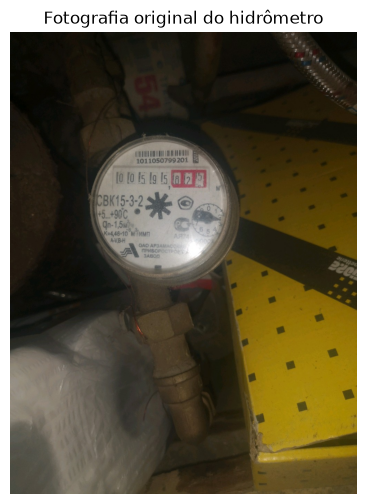

In [13]:
# Parte 2 - Visualização de uma imagem original

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Seleciona uma imagem do dataset
nome_imagem = df.iloc[0]["photo_name"]

# Define o caminho da fotografia original
caminho_imagem = Path("data/WaterMeters/images") / nome_imagem

print("Nome da imagem:", nome_imagem)
print("Arquivo encontrado:", caminho_imagem.exists())

# Abre e apresenta a fotografia
if caminho_imagem.exists():

    imagem = Image.open(caminho_imagem)

    print("Dimensões:", imagem.size)

    plt.figure(figsize=(10, 6))
    plt.imshow(imagem)
    plt.title("Fotografia original do hidrômetro")
    plt.axis("off")
    plt.show()

Máscara encontrada: True
Dimensões da máscara: (1000, 1333)
Modo da imagem: L


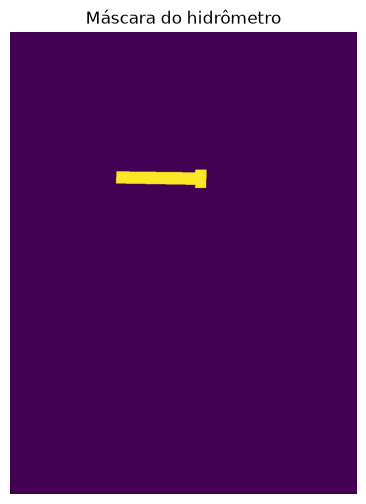

In [14]:
# Parte 2 - Visualização da máscara correspondente

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Utiliza o mesmo nome da fotografia anterior
nome_imagem = df.iloc[0]["photo_name"]

# Localiza a máscara
caminho_mascara = Path("data/WaterMeters/masks") / nome_imagem

print("Máscara encontrada:", caminho_mascara.exists())

if caminho_mascara.exists():

    mascara = Image.open(caminho_mascara)

    print("Dimensões da máscara:", mascara.size)
    print("Modo da imagem:", mascara.mode)

    plt.figure(figsize=(8, 6))
    plt.imshow(mascara)
    plt.title("Máscara do hidrômetro")
    plt.axis("off")
    plt.show()

In [15]:
# Parte 2 - Investigação das coordenadas do visor

import ast
from pprint import pprint

# Seleciona a anotação da primeira fotografia
location_texto = df.iloc[0]["location"]

# Converte o texto em uma estrutura Python
location = ast.literal_eval(location_texto)

print("TIPO DA ANOTAÇÃO:")
print(location["type"])

print("\nESTRUTURA COMPLETA:")
pprint(location)

print("\nQUANTIDADE DE PONTOS:")
print(len(location["data"]))

TIPO DA ANOTAÇÃO:
polygon

ESTRUTURA COMPLETA:
{'data': [{'x': 0.30788, 'y': 0.30207},
          {'x': 0.30676, 'y': 0.32731},
          {'x': 0.53501, 'y': 0.33068},
          {'x': 0.53445, 'y': 0.33699},
          {'x': 0.56529, 'y': 0.33741},
          {'x': 0.56697, 'y': 0.29786},
          {'x': 0.53501, 'y': 0.29786},
          {'x': 0.53445, 'y': 0.30417}],
 'type': 'polygon'}

QUANTIDADE DE PONTOS:
8


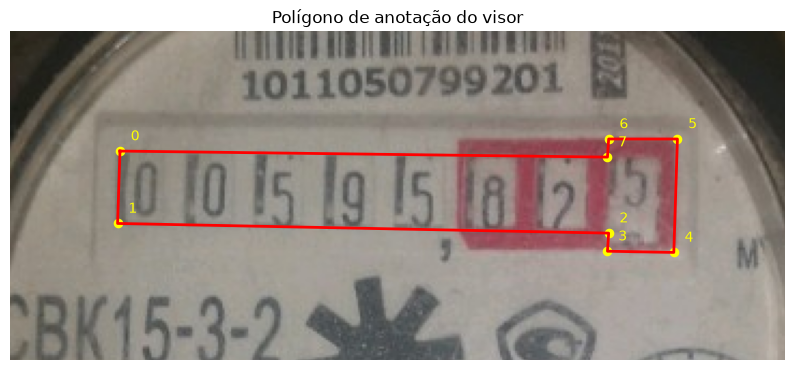

In [16]:
# Parte 2 - Visualização do polígono do visor

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Abre a fotografia original
nome_imagem = df.iloc[0]["photo_name"]

caminho = Path("data/WaterMeters/images") / nome_imagem

imagem = Image.open(caminho)

largura, altura = imagem.size

# Converte os pontos normalizados em pixels
pontos = np.array([
    [p["x"] * largura, p["y"] * altura]
    for p in location["data"]
])

# Fecha o contorno do polígono
pontos_fechados = np.vstack([pontos, pontos[0]])

# Exibe a fotografia com o polígono
plt.figure(figsize=(10, 8))

plt.imshow(imagem)

plt.plot(
    pontos_fechados[:, 0],
    pontos_fechados[:, 1],
    color="red",
    linewidth=2
)

# Identifica cada ponto do polígono
for i, (x, y) in enumerate(pontos):
    plt.scatter(x, y, color="yellow", s=35)
    plt.text(x + 5, y - 5, str(i), color="yellow", fontsize=10)

# Amplia a região do visor
plt.xlim(pontos[:, 0].min() - 50, pontos[:, 0].max() + 50)
plt.ylim(pontos[:, 1].max() + 50, pontos[:, 1].min() - 50)

plt.title("Polígono de anotação do visor")
plt.axis("off")
plt.show()

In [17]:
# Parte 2 - Análise da quantidade de pontos dos polígonos

import ast
from collections import Counter

quantidade_pontos = []

# Percorre todas as anotações
for anotacao in df["location"]:

    # Converte a anotação textual em dicionário
    poligono = ast.literal_eval(anotacao)

    # Conta quantos pontos existem
    quantidade_pontos.append(len(poligono["data"]))

# Conta a frequência de cada quantidade
frequencia = Counter(quantidade_pontos)

print("QUANTIDADE DE PONTOS DOS POLÍGONOS:")

for pontos, quantidade in sorted(frequencia.items()):
    print(f"{pontos} pontos: {quantidade} imagens")

QUANTIDADE DE PONTOS DOS POLÍGONOS:
4 pontos: 505 imagens
6 pontos: 508 imagens
8 pontos: 231 imagens


In [18]:
# Parte 2 - Seleção de exemplos por tipo de polígono

import ast
import pandas as pd

# Cria uma cópia da tabela original
df_poligonos = df.copy()

# Calcula a quantidade de pontos de cada anotação
df_poligonos["n_pontos"] = df_poligonos["location"].apply(
    lambda texto: len(ast.literal_eval(texto)["data"])
)

# Seleciona um exemplo de cada tipo
exemplos = df_poligonos[
    df_poligonos["n_pontos"].isin([4, 6, 8])
].groupby("n_pontos").head(1)

print("EXEMPLOS SELECIONADOS:")
display(exemplos[["photo_name", "value", "n_pontos"]])

EXEMPLOS SELECIONADOS:


,photo_name,value,n_pontos
0,id_53_value_595_825.jpg,595.825,8
1,id_553_value_65_475.jpg,65.475,6
2,id_407_value_21_86.jpg,21.860,4


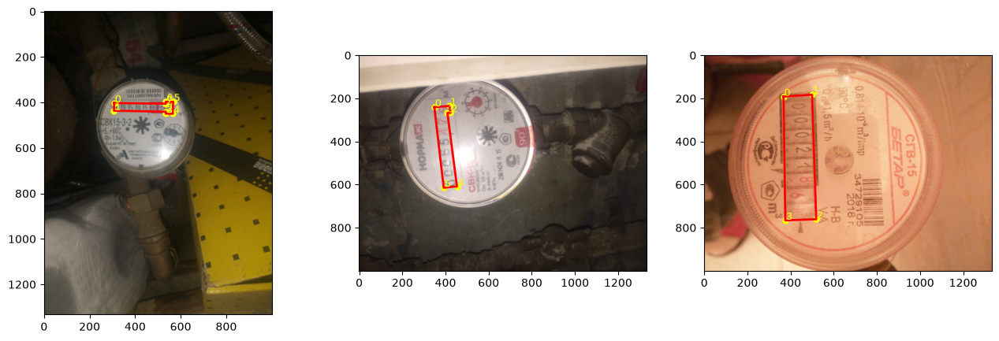

In [19]:
# Parte 2 - Comparação visual dos polígonos

import ast
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (_, linha) in zip(axes, exemplos.iterrows()):

    # Abre a fotografia
    caminho = Path("data/WaterMeters/images") / linha["photo_name"]
    imagem = Image.open(caminho)

    largura, altura = imagem.size

    # Recupera os pontos do polígono
    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ])

    # Fecha o contorno
    pontos_fechados = np.vstack([pontos, pontos[0]])

    # Mostra a imagem e o contorno
    ax.imshow(imagem)

    ax.plot(
        pontos_fechados[:, 0],
        pontos_fechados[:, 1],
        color="red",
        linewidth=2
    )

    # Numera os vértices
    for i, (x, y) in enumerate(pontos):
        ax.scatter(x, y, color="yellow", s=25)
        ax.text(x + 3, y - 3, str(i), color="yellow", fontsize=9)

    # Amplia a região do visor
    margem = 30

In [20]:
# Parte 2 - Análise preliminar da orientação dos visores

import ast
import numpy as np
import pandas as pd

resultados_orientacao = []

for _, linha in df_poligonos.iterrows():

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"], p["y"]]
        for p in anotacao["data"]
    ])

    # Calcula a extensão horizontal e vertical do polígono
    largura = pontos[:, 0].max() - pontos[:, 0].min()
    altura = pontos[:, 1].max() - pontos[:, 1].min()

    # Classificação preliminar da orientação
    # Usamos coordenadas normalizadas, portanto é uma aproximação
    if largura > altura:
        orientacao = "horizontal_aparente"
    else:
        orientacao = "vertical_aparente"

    resultados_orientacao.append({
        "photo_name": linha["photo_name"],
        "n_pontos": linha["n_pontos"],
        "orientacao_aparente": orientacao
    })

df_orientacao = pd.DataFrame(resultados_orientacao)

print("ORIENTAÇÃO APARENTE DOS POLÍGONOS:")
print(df_orientacao["orientacao_aparente"].value_counts())

print("\nORIENTAÇÃO POR QUANTIDADE DE PONTOS:")
display(pd.crosstab(
    df_orientacao["n_pontos"],
    df_orientacao["orientacao_aparente"]
))

ORIENTAÇÃO APARENTE DOS POLÍGONOS:
orientacao_aparente
horizontal_aparente    1150
vertical_aparente        94
Name: count, dtype: int64

ORIENTAÇÃO POR QUANTIDADE DE PONTOS:


orientacao_aparente,horizontal_aparente,vertical_aparente
n_pontos,,
4,466,39
6,471,37
8,213,18


In [21]:
# Parte 2 - Orientação dos visores em coordenadas reais

import ast
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

resultados = []

# Considera apenas as imagens do split oficial
df_validos = df[df["photo_name"].isin(splits["photo_name"])].copy()

for _, linha in df_validos.iterrows():

    nome = linha["photo_name"]

    # Localiza a fotografia
    caminho = Path("data/WaterMeters/images") / nome

    # Obtém as dimensões reais da fotografia
    with Image.open(caminho) as imagem:
        largura_img, altura_img = imagem.size

    # Recupera os pontos do polígono
    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura_img, p["y"] * altura_img]
        for p in anotacao["data"]
    ])

    # Calcula as dimensões da região anotada em pixels
    largura_visor = np.ptp(pontos[:, 0])
    altura_visor = np.ptp(pontos[:, 1])

    # Identifica a orientação geométrica aparente
    if largura_visor >= altura_visor:
        orientacao = "horizontal"
    else:
        orientacao = "vertical"

    resultados.append({
        "photo_name": nome,
        "orientacao": orientacao,
        "n_pontos": len(pontos),
        "largura_visor": largura_visor,
        "altura_visor": altura_visor
    })

df_orientacao_corrigida = pd.DataFrame(resultados)

print("ORIENTAÇÃO GEOMÉTRICA DOS VISORES:")
print(df_orientacao_corrigida["orientacao"].value_counts())

print("\nORIENTAÇÃO POR QUANTIDADE DE PONTOS:")
display(pd.crosstab(
    df_orientacao_corrigida["n_pontos"],
    df_orientacao_corrigida["orientacao"]
))

print("\nTOTAL DE IMAGENS ANALISADAS:")
print(len(df_orientacao_corrigida))

ORIENTAÇÃO GEOMÉTRICA DOS VISORES:
orientacao
horizontal    1142
vertical       101
Name: count, dtype: int64

ORIENTAÇÃO POR QUANTIDADE DE PONTOS:


orientacao,horizontal,vertical
n_pontos,,
4,462,43
6,467,41
8,213,17



TOTAL DE IMAGENS ANALISADAS:
1243


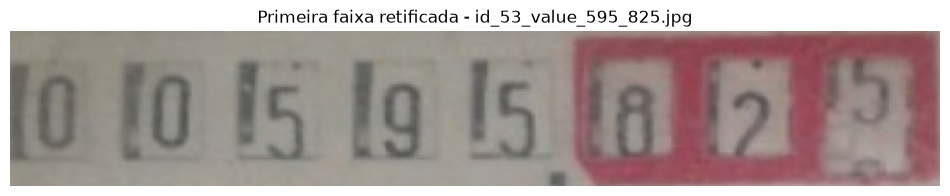

Dimensões da faixa: (64, 384, 3)


In [22]:
# Parte 3 - Primeira retificação do visor

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona a primeira fotografia
linha = df_validos.iloc[0]

nome = linha["photo_name"]
caminho = Path("data/WaterMeters/images") / nome

# Abre a fotografia
imagem = cv2.imread(str(caminho))

# Converte a imagem de BGR para RGB
imagem_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

altura, largura = imagem_rgb.shape[:2]

# Recupera as coordenadas do polígono
anotacao = ast.literal_eval(linha["location"])

pontos = np.array([
    [p["x"] * largura, p["y"] * altura]
    for p in anotacao["data"]
], dtype=np.float32)

# Aproximação inicial: retângulo mínimo que contém o polígono
retangulo = cv2.minAreaRect(pontos)
cantos = cv2.boxPoints(retangulo)

# Organiza os cantos para a transformação
soma = cantos.sum(axis=1)
diferenca = np.diff(cantos, axis=1).ravel()

origem = np.array([
    cantos[np.argmin(soma)],
    cantos[np.argmin(diferenca)],
    cantos[np.argmax(soma)],
    cantos[np.argmax(diferenca)]
], dtype=np.float32)

# Define o retângulo de destino: 384 x 64 pixels
destino = np.array([
    [0, 0],
    [383, 0],
    [383, 63],
    [0, 63]
], dtype=np.float32)

# Calcula e aplica a transformação de perspectiva
matriz = cv2.getPerspectiveTransform(origem, destino)

faixa = cv2.warpPerspective(
    imagem_rgb,
    matriz,
    (384, 64)
)

# Mostra o resultado
plt.figure(figsize=(12, 3))
plt.imshow(faixa)
plt.title(f"Primeira faixa retificada - {nome}")
plt.axis("off")
plt.show()

print("Dimensões da faixa:", faixa.shape)

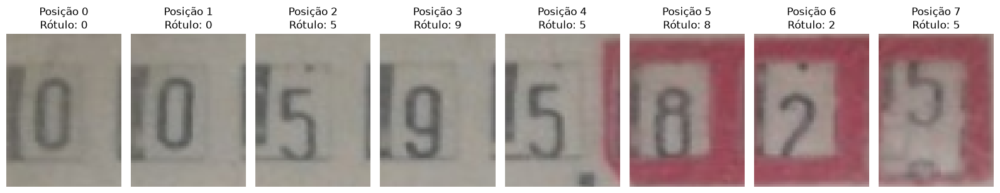

Quantidade de recortes: 8
Dimensão de cada recorte: (64, 48, 3)


In [23]:
# Parte 3 - Teste da divisão da faixa em oito dígitos

import matplotlib.pyplot as plt

# Rótulo esperado da primeira fotografia
rotulo = "00595825"

# Divide a faixa em oito recortes de 48 pixels
recortes = []

for posicao in range(8):
    inicio = posicao * 48
    fim = inicio + 48

    recorte = faixa[:, inicio:fim]
    recortes.append(recorte)

# Mostra os oito recortes lado a lado
fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i, ax in enumerate(axes):
    ax.imshow(recortes[i])
    ax.set_title(f"Posição {i}\nRótulo: {rotulo[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Confere as dimensões
print("Quantidade de recortes:", len(recortes))
print("Dimensão de cada recorte:", recortes[0].shape)

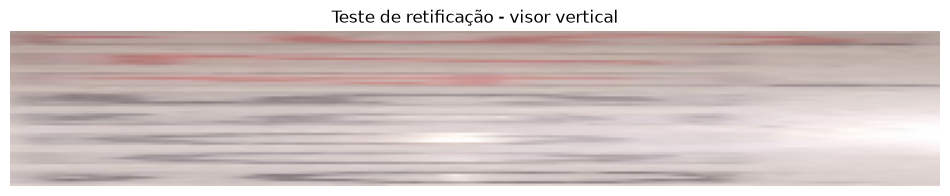

Dimensões: (64, 384, 3)


In [24]:
# Parte 3 - Teste da retificação em visor vertical

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona uma fotografia com visor vertical
nome = "id_553_value_65_475.jpg"

linha = df[df["photo_name"] == nome].iloc[0]

# Abre a fotografia
caminho = Path("data/WaterMeters/images") / nome
imagem = cv2.imread(str(caminho))
imagem_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

altura, largura = imagem_rgb.shape[:2]

# Recupera o polígono
anotacao = ast.literal_eval(linha["location"])

pontos = np.array([
    [p["x"] * largura, p["y"] * altura]
    for p in anotacao["data"]
], dtype=np.float32)

# Calcula o retângulo envolvente
retangulo = cv2.minAreaRect(pontos)
cantos = cv2.boxPoints(retangulo)

# Organiza os quatro pontos
soma = cantos.sum(axis=1)
diferenca = np.diff(cantos, axis=1).ravel()

origem = np.array([
    cantos[np.argmin(soma)],
    cantos[np.argmin(diferenca)],
    cantos[np.argmax(soma)],
    cantos[np.argmax(diferenca)]
], dtype=np.float32)

# Define o destino
destino = np.array([
    [0, 0],
    [383, 0],
    [383, 63],
    [0, 63]
], dtype=np.float32)

# Aplica a transformação
matriz = cv2.getPerspectiveTransform(origem, destino)

faixa_vertical = cv2.warpPerspective(
    imagem_rgb,
    matriz,
    (384, 64)
)

# Visualiza o resultado
plt.figure(figsize=(12, 3))
plt.imshow(faixa_vertical)
plt.title("Teste de retificação - visor vertical")
plt.axis("off")
plt.show()

print("Dimensões:", faixa_vertical.shape)

In [7]:
# Parte 3 - Correção da retificação de um visor vertical

import cv2
import numpy as np
import matplotlib.pyplot as plt

def retificar_visor(imagem_rgb, pontos, largura=384, altura=64):

    # Encontra o retângulo rotacionado mínimo
    retangulo = cv2.minAreaRect(pontos.astype(np.float32))

    # Obtém os quatro vértices
    cantos = cv2.boxPoints(retangulo)

    # Organiza os cantos em ordem circular
    centro = cantos.mean(axis=0)

    angulos = np.arctan2(
        cantos[:, 1] - centro[1],
        cantos[:, 0] - centro[0]
    )

    cantos = cantos[np.argsort(angulos)]

    # Coloca o canto superior esquerdo como primeiro
    inicio = np.argmin(cantos.sum(axis=1))
    cantos = np.roll(cantos, -inicio, axis=0)

    # Calcula o comprimento dos lados
    lado_01 = np.linalg.norm(cantos[1] - cantos[0])
    lado_12 = np.linalg.norm(cantos[2] - cantos[1])

    # Destino horizontal
    destino = np.array([
        [0, 0],
        [largura - 1, 0],
        [largura - 1, altura - 1],
        [0, altura - 1]
    ], dtype=np.float32)

    # Se o primeiro lado for o menor, reorganiza os pontos
    if lado_01 < lado_12:
        cantos = np.roll(cantos, -1, axis=0)

    # Calcula a transformação
    matriz = cv2.getPerspectiveTransform(
        cantos.astype(np.float32),
        destino
    )

    # Produz a faixa retificada
    faixa = cv2.warpPerspective(
        imagem_rgb,
        matriz,
        (largura, altura)
    )

    return faixa



In [8]:
print("Função retificar_visor disponível:",
      callable(retificar_visor))

Função retificar_visor disponível: True


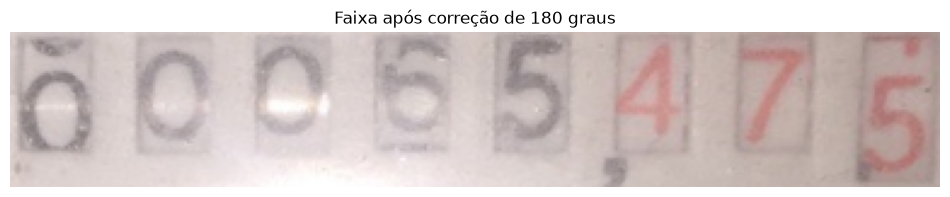

Dimensões: (64, 384, 3)


In [26]:
# Parte 3 - Correção da orientação da faixa

import cv2
import matplotlib.pyplot as plt

# Gira a faixa em 180 graus
faixa_orientada = cv2.rotate(
    faixa_corrigida,
    cv2.ROTATE_180
)

# Mostra a faixa após a correção
plt.figure(figsize=(12, 3))
plt.imshow(faixa_orientada)
plt.title("Faixa após correção de 180 graus")
plt.axis("off")
plt.show()

print("Dimensões:", faixa_orientada.shape)

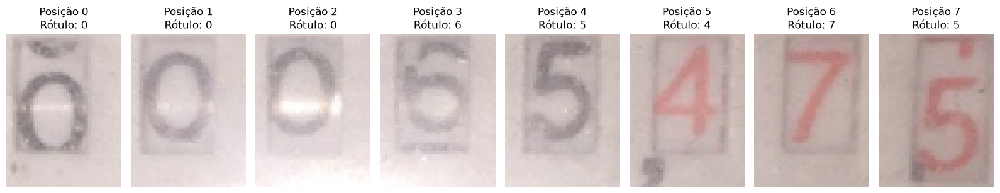

In [27]:
# Parte 3 - Verificação dos recortes do visor corrigido

import matplotlib.pyplot as plt

rotulo_esperado = "00065475"

fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for posicao in range(8):

    inicio = posicao * 48
    fim = inicio + 48

    recorte = faixa_orientada[:, inicio:fim]

    axes[posicao].imshow(recorte)
    axes[posicao].set_title(
        f"Posição {posicao}\n"
        f"Rótulo: {rotulo_esperado[posicao]}"
    )
    axes[posicao].axis("off")

plt.tight_layout()
plt.show()

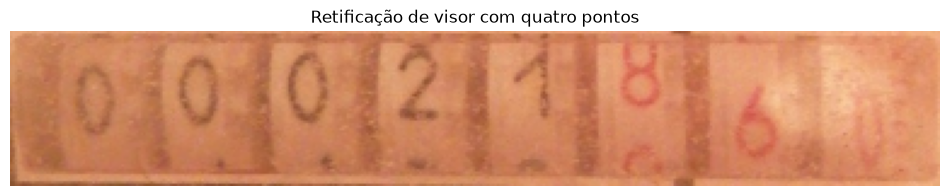

Dimensões: (64, 384, 3)


In [28]:
# Parte 3 - Retificação de um polígono com quatro pontos

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona a terceira fotografia
nome = "id_407_value_21_86.jpg"

linha = df[df["photo_name"] == nome].iloc[0]

# Abre a fotografia
caminho = Path("data/WaterMeters/images") / nome
imagem = cv2.imread(str(caminho))

imagem_rgb = cv2.cvtColor(
    imagem,
    cv2.COLOR_BGR2RGB
)

altura, largura = imagem_rgb.shape[:2]

# Recupera o polígono
anotacao = ast.literal_eval(linha["location"])

pontos = np.array([
    [p["x"] * largura, p["y"] * altura]
    for p in anotacao["data"]
], dtype=np.float32)

# Aplica a função criada anteriormente
faixa_teste = retificar_visor(imagem_rgb, pontos)

# Mostra o resultado
plt.figure(figsize=(12, 3))
plt.imshow(faixa_teste)
plt.title("Retificação de visor com quatro pontos")
plt.axis("off")
plt.show()

print("Dimensões:", faixa_teste.shape)

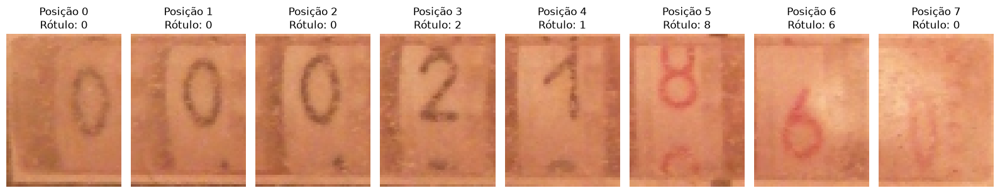

Quantidade de recortes: 8
Dimensões de cada recorte: (64, 48, 3)


In [29]:
# Parte 3 - Verificação dos recortes do visor com 4 pontos

import matplotlib.pyplot as plt

rotulo_esperado = "00021860"

fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for posicao in range(8):

    inicio = posicao * 48
    fim = inicio + 48

    recorte = faixa_teste[:, inicio:fim]

    axes[posicao].imshow(recorte)
    axes[posicao].set_title(
        f"Posição {posicao}\n"
        f"Rótulo: {rotulo_esperado[posicao]}"
    )
    axes[posicao].axis("off")

plt.tight_layout()
plt.show()

print("Quantidade de recortes:", 8)
print("Dimensões de cada recorte:", faixa_teste[:, 0:48].shape)

In [30]:
# Parte 3 - Controle inicial das orientações

import pandas as pd

controle_orientacao = df_orientacao_corrigida[
    ["photo_name", "n_pontos", "orientacao"]
].copy()

# Registra o estado das verificações
controle_orientacao["orientacao_validada"] = False

# Correção ainda não determinada
controle_orientacao["rotacao_necessaria"] = pd.NA

# Qualidade ainda não avaliada
controle_orientacao["qualidade_recorte"] = "nao_avaliado"

print("TOTAL DE IMAGENS:")
print(len(controle_orientacao))

print("\nCONTROLE INICIAL:")
display(controle_orientacao.head())

print("\nIMAGENS PENDENTES DE VALIDAÇÃO:")
print((~controle_orientacao["orientacao_validada"]).sum())

TOTAL DE IMAGENS:
1243

CONTROLE INICIAL:


,photo_name,n_pontos,orientacao,orientacao_validada,rotacao_necessaria,qualidade_recorte
0,id_53_value_595_825.jpg,8,horizontal,False,<NA>,nao_avaliado
1,id_553_value_65_475.jpg,6,vertical,False,<NA>,nao_avaliado
2,id_407_value_21_86.jpg,4,vertical,False,<NA>,nao_avaliado
3,id_252_value_313_322.jpg,4,horizontal,False,<NA>,nao_avaliado
4,id_851_value_305_162.jpg,8,horizontal,False,<NA>,nao_avaliado



IMAGENS PENDENTES DE VALIDAÇÃO:
1243


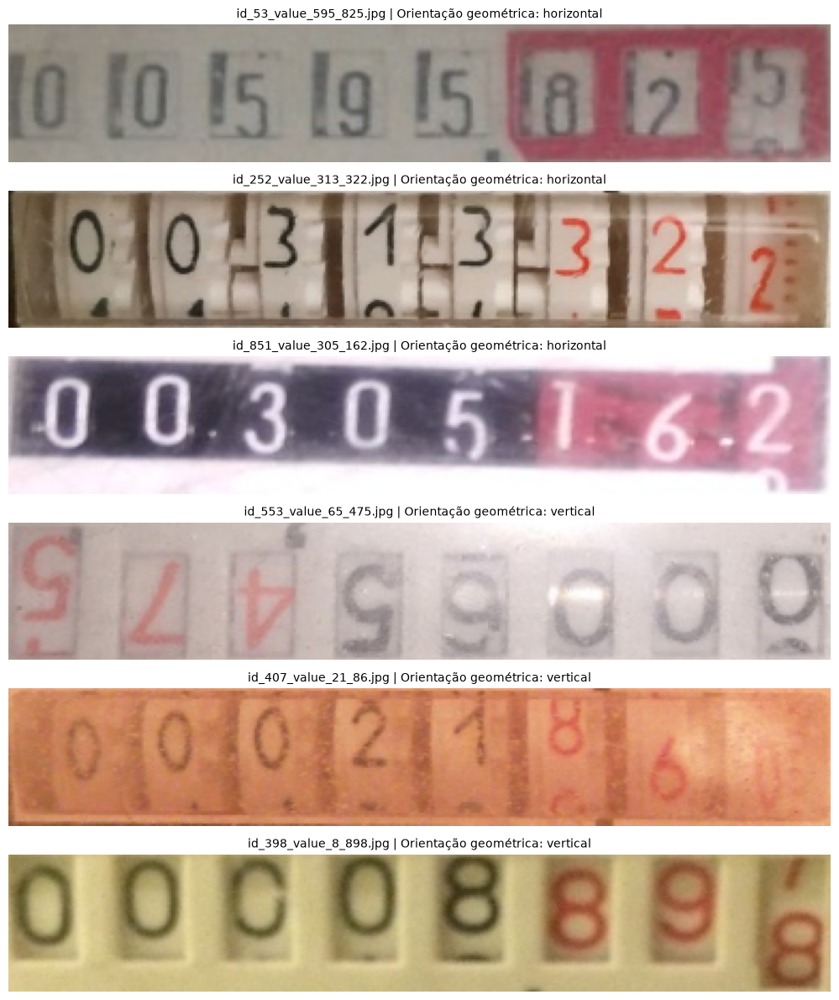

In [31]:
# Parte 3 - Galeria de inspeção das faixas

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona três visores horizontais e três verticais
amostra_horizontal = df_orientacao_corrigida[
    df_orientacao_corrigida["orientacao"] == "horizontal"
].head(3)

amostra_vertical = df_orientacao_corrigida[
    df_orientacao_corrigida["orientacao"] == "vertical"
].head(3)

amostra = pd.concat([
    amostra_horizontal,
    amostra_vertical
])

fig, axes = plt.subplots(6, 1, figsize=(12, 12))

for ax, (_, item) in zip(axes, amostra.iterrows()):

    nome = item["photo_name"]

    linha = df[df["photo_name"] == nome].iloc[0]

    caminho = Path("data/WaterMeters/images") / nome
    imagem = cv2.imread(str(caminho))

    imagem_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    altura, largura = imagem_rgb.shape[:2]

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Aplica a função de retificação criada anteriormente
    faixa_resultado = retificar_visor(imagem_rgb, pontos)

    ax.imshow(faixa_resultado)
    ax.set_title(
        f"{nome} | Orientação geométrica: {item['orientacao']}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [33]:
# Parte 3 - Registro das primeiras verificações de orientação

# Imagens cuja orientação foi conferida visualmente
imagens_corretas = [
    "id_53_value_595_825.jpg",
    "id_252_value_313_322.jpg",
    "id_851_value_305_162.jpg",
    "id_407_value_21_86.jpg",
    "id_398_value_8_898.jpg"
]

# Imagens que precisam de rotação de 180 graus
imagens_invertidas = [
    "id_553_value_65_475.jpg"
]

# Registra as imagens já corretas
mascara_corretas = controle_orientacao[
    "photo_name"
].isin(imagens_corretas)

controle_orientacao.loc[
    mascara_corretas, "orientacao_validada"
] = True

controle_orientacao.loc[
    mascara_corretas, "rotacao_necessaria"
] = 0

# Registra as imagens invertidas
mascara_invertidas = controle_orientacao[
    "photo_name"
].isin(imagens_invertidas)

controle_orientacao.loc[
    mascara_invertidas, "orientacao_validada"
] = True

controle_orientacao.loc[
    mascara_invertidas, "rotacao_necessaria"
] = 180

# Exibe os resultados
print("Imagens validadas:")
print(controle_orientacao["orientacao_validada"].sum())

print("\nImagens pendentes:")
print((~controle_orientacao["orientacao_validada"]).sum())

print("\nCorreções de 180 graus identificadas:")
print((controle_orientacao["rotacao_necessaria"] == 180).sum())

print("\nRegistros verificados:")
display(
    controle_orientacao[
        controle_orientacao["orientacao_validada"]
    ]
)

Imagens validadas:
6

Imagens pendentes:
1237

Correções de 180 graus identificadas:
1

Registros verificados:


,photo_name,n_pontos,orientacao,orientacao_validada,rotacao_necessaria,qualidade_recorte
0,id_53_value_595_825.jpg,8,horizontal,True,0,nao_avaliado
1,id_553_value_65_475.jpg,6,vertical,True,180,nao_avaliado
2,id_407_value_21_86.jpg,4,vertical,True,0,nao_avaliado
3,id_252_value_313_322.jpg,4,horizontal,True,0,nao_avaliado
4,id_851_value_305_162.jpg,8,horizontal,True,0,nao_avaliado
5,id_398_value_8_898.jpg,6,vertical,True,0,nao_avaliado


In [34]:
# Parte 3 - Salvar o controle de orientação

from pathlib import Path

# Cria uma pasta para os arquivos de controle
pasta_controle = Path("data/controle")
pasta_controle.mkdir(parents=True, exist_ok=True)

# Define o caminho do arquivo
caminho_csv = pasta_controle / "controle_orientacao.csv"

# Salva a tabela
controle_orientacao.to_csv(
    caminho_csv,
    index=False,
    encoding="utf-8"
)

print("Controle salvo com sucesso!")
print("Localização:", caminho_csv.resolve())
print("Total de registros:", len(controle_orientacao))

Controle salvo com sucesso!
Localização: C:\Users\Arnóbio\OneDrive\Desktop\CESAR SCHOOL\Visão Computacional\Pratica_2_Hidrometros\vc-20262-p2\data\controle\controle_orientacao.csv
Total de registros: 1243


In [35]:
# Parte 3 - Recuperação do controle de orientação

import pandas as pd
from pathlib import Path

caminho_csv = Path("data/controle/controle_orientacao.csv")

# Carrega o controle salvo
controle_recuperado = pd.read_csv(caminho_csv)

print("Arquivo recuperado com sucesso!")

print("\nTotal de imagens:")
print(len(controle_recuperado))

print("\nImagens validadas:")
print(controle_recuperado["orientacao_validada"].sum())

print("\nImagens pendentes:")
print((~controle_recuperado["orientacao_validada"]).sum())

print("\nCorreções de 180 graus:")
print((controle_recuperado["rotacao_necessaria"] == 180).sum())

Arquivo recuperado com sucesso!

Total de imagens:
1243

Imagens validadas:
6

Imagens pendentes:
1237

Correções de 180 graus:
1


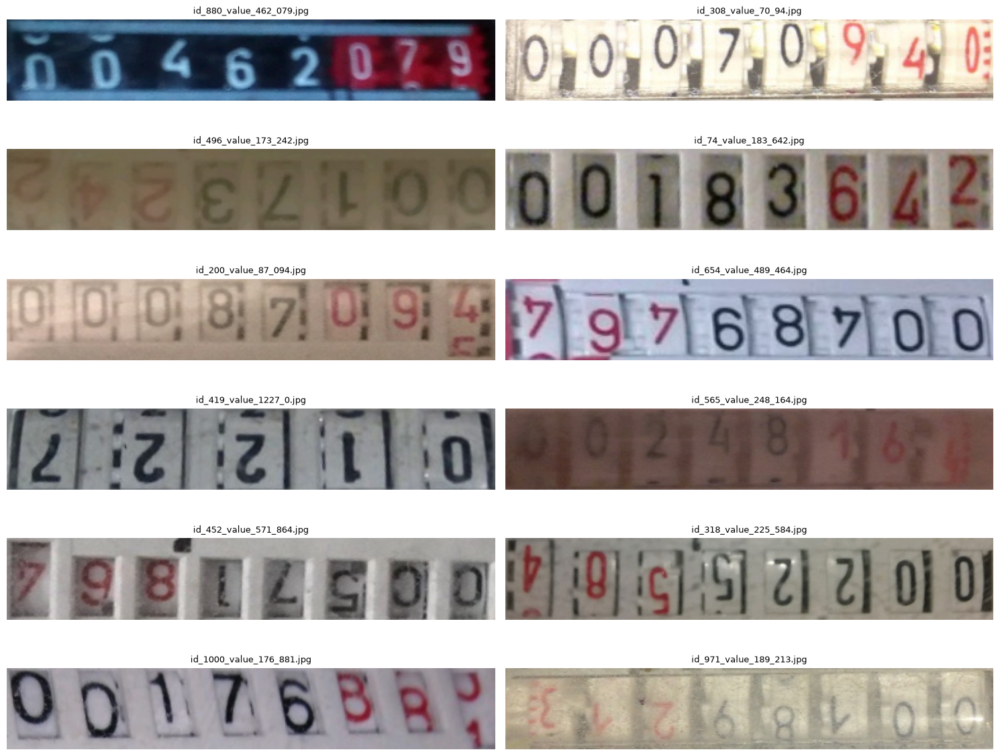

In [36]:
# Parte 3 - Galeria de inspeção dos visores verticais

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona imagens verticais ainda não verificadas
pendentes = controle_recuperado[
    (controle_recuperado["orientacao"] == "vertical") &
    (~controle_recuperado["orientacao_validada"])
]

# Seleciona as primeiras 12
amostra = pendentes.head(12)

fig, axes = plt.subplots(6, 2, figsize=(15, 12))

axes = axes.flatten()

for ax, (_, item) in zip(axes, amostra.iterrows()):

    nome = item["photo_name"]

    # Recupera a anotação
    linha = df[df["photo_name"] == nome].iloc[0]

    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    imagem_rgb = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Retificação preliminar
    faixa = retificar_visor(imagem_rgb, pontos)

    ax.imshow(faixa)
    ax.set_title(nome, fontsize=9)
    ax.axis("off")

# Oculta painéis não utilizados, caso existam
for ax in axes[len(amostra):]:
    ax.axis("off")

plt.tight_layout()

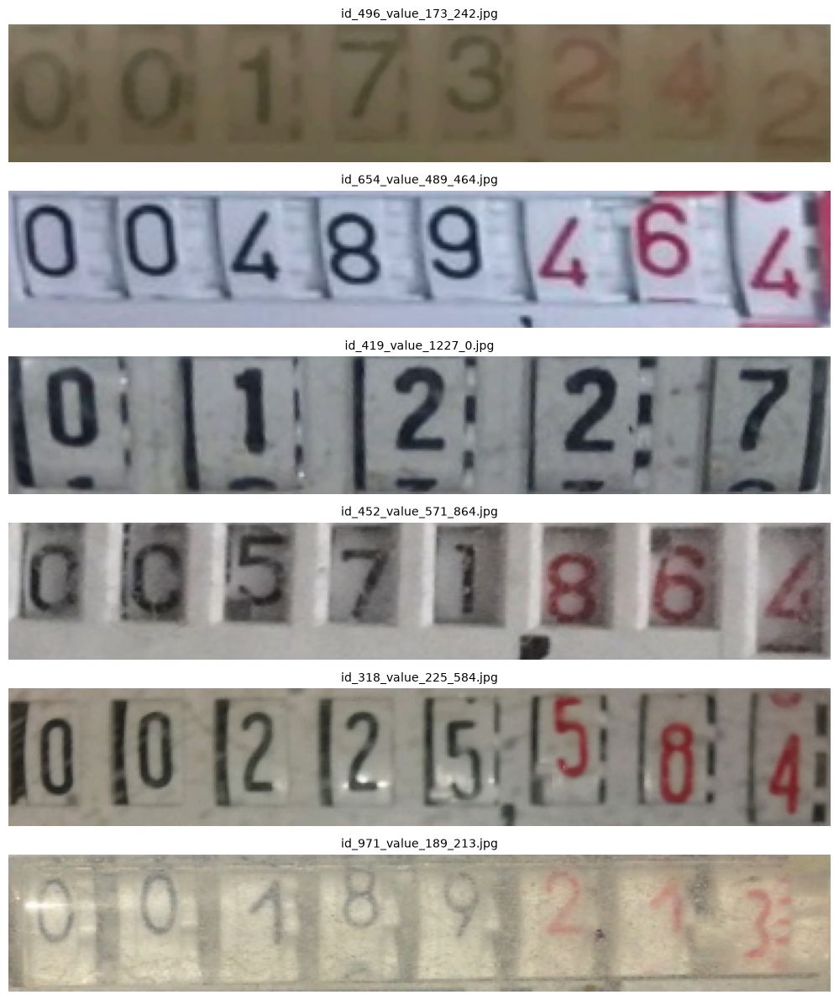

Quantidade de faixas corrigidas para inspeção: 6


In [38]:
# Parte 3 - Conferência das faixas invertidas

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

imagens_invertidas_lote = [
    "id_496_value_173_242.jpg",
    "id_654_value_489_464.jpg",
    "id_419_value_1227_0.jpg",
    "id_452_value_571_864.jpg",
    "id_318_value_225_584.jpg",
    "id_971_value_189_213.jpg"
]

fig, axes = plt.subplots(6, 1, figsize=(12, 12))

for ax, nome in zip(axes, imagens_invertidas_lote):

    # Localiza a anotação da fotografia
    linha = df[df["photo_name"] == nome].iloc[0]

    # Abre a fotografia original
    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    imagem_rgb = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    # Recupera as coordenadas do polígono
    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Aplica a função de retificação
    faixa = retificar_visor(imagem_rgb, pontos)

    # Corrige a orientação em 180 graus
    faixa_corrigida = cv2.rotate(
        faixa,
        cv2.ROTATE_180
    )

    # Exibe a faixa corrigida
    ax.imshow(faixa_corrigida)
    ax.set_title(nome, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Quantidade de faixas corrigidas para inspeção:",
      len(imagens_invertidas_lote))

In [39]:
# Parte 3 - Atualização do controle de orientação

import pandas as pd
from pathlib import Path

caminho_csv = Path("data/controle/controle_orientacao.csv")

# Recupera o controle salvo
controle_orientacao = pd.read_csv(caminho_csv)

# Imagens corrigidas e verificadas
novas_corrigidas = [
    "id_496_value_173_242.jpg",
    "id_654_value_489_464.jpg",
    "id_419_value_1227_0.jpg",
    "id_452_value_571_864.jpg",
    "id_318_value_225_584.jpg",
    "id_971_value_189_213.jpg"
]

# Identifica as linhas correspondentes
mascara = controle_orientacao["photo_name"].isin(
    novas_corrigidas
)

# Registra a conferência da orientação
controle_orientacao.loc[
    mascara, "orientacao_validada"
] = True

controle_orientacao.loc[
    mascara, "rotacao_necessaria"
] = 180

# Registra o problema observado em id_419
controle_orientacao.loc[
    controle_orientacao["photo_name"] == "id_419_value_1227_0.jpg",
    "qualidade_recorte"
] = "faixa_incompleta_a_revisar"

# Salva o controle atualizado
controle_orientacao.to_csv(
    caminho_csv,
    index=False
)

print("Imagens com orientação validada:",
      controle_orientacao["orientacao_validada"].sum())

print("Imagens pendentes:",
      (~controle_orientacao["orientacao_validada"]).sum())

print("Rotações de 180 graus registradas:",
      (controle_orientacao["rotacao_necessaria"] == 180).sum())

print("Arquivo atualizado com sucesso!")

Imagens com orientação validada: 12
Imagens pendentes: 1231
Rotações de 180 graus registradas: 7
Arquivo atualizado com sucesso!


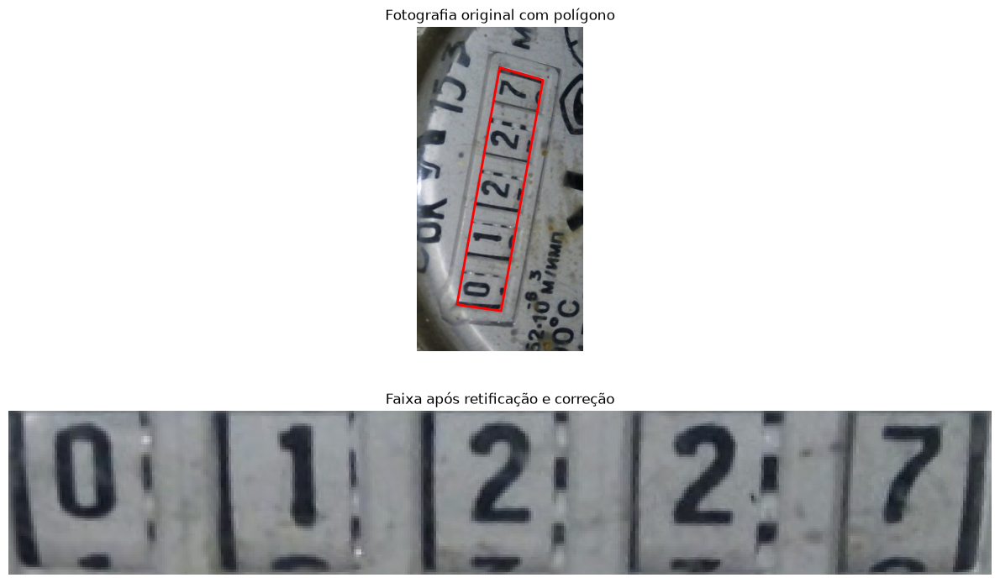

Leitura esperada: 01227,000
Quantidade de pontos: 4


In [41]:
# Parte 3 - Investigação de uma faixa incompleta

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

nome = "id_419_value_1227_0.jpg"

# Localiza o registro
linha = df[df["photo_name"] == nome].iloc[0]

# Abre a fotografia
caminho = Path("data/WaterMeters/images") / nome
imagem = cv2.imread(str(caminho))
imagem_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

altura, largura = imagem_rgb.shape[:2]

# Recupera o polígono original
anotacao = ast.literal_eval(linha["location"])

pontos = np.array([
    [p["x"] * largura, p["y"] * altura]
    for p in anotacao["data"]
], dtype=np.float32)

# Retifica a imagem
faixa = retificar_visor(imagem_rgb, pontos)

# Corrige a orientação
faixa_corrigida = cv2.rotate(
    faixa,
    cv2.ROTATE_180
)

# Exibe duas visualizações
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Fotografia original com polígono
pontos_fechados = np.vstack([pontos, pontos[0]])

axes[0].imshow(imagem_rgb)
axes[0].plot(
    pontos_fechados[:, 0],
    pontos_fechados[:, 1],
    color="red",
    linewidth=2
)

# Amplia a região do visor
margem = 50

axes[0].set_xlim(
    pontos[:, 0].min() - margem,
    pontos[:, 0].max() + margem
)

axes[0].set_ylim(
    pontos[:, 1].max() + margem,
    pontos[:, 1].min() - margem
)

axes[0].set_title("Fotografia original com polígono")
axes[0].axis("off")

# Mostra a faixa retificada
axes[1].imshow(faixa_corrigida)
axes[1].set_title("Faixa após retificação e correção")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Leitura esperada: 01227,000")
print("Quantidade de pontos:", len(pontos))

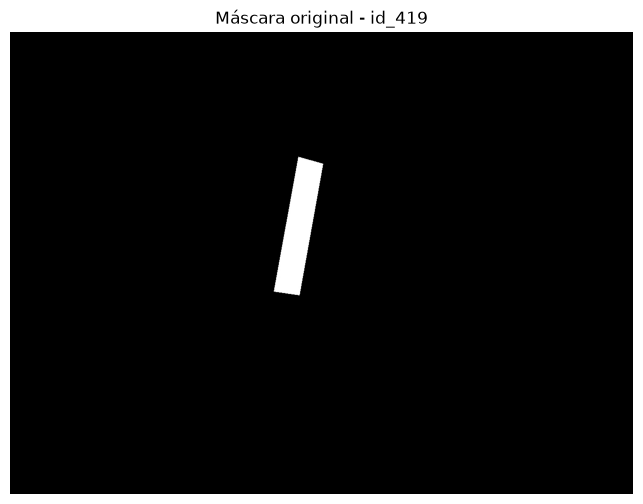

Dimensões: (1349, 1000)


In [42]:
# Parte 3 - Inspeção da máscara da imagem problemática

from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

nome = "id_419_value_1227_0.jpg"

caminho_mascara = Path("data/WaterMeters/masks") / nome

mascara = Image.open(caminho_mascara)

plt.figure(figsize=(10, 6))
plt.imshow(mascara, cmap="gray")
plt.title("Máscara original - id_419")
plt.axis("off")
plt.show()

print("Dimensões:", mascara.size)

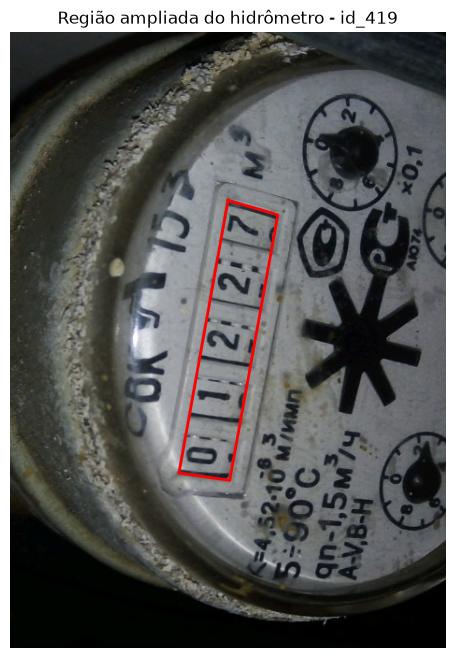

In [43]:
# Parte 3 - Investigação da região ao redor do visor

import matplotlib.pyplot as plt
import numpy as np

# Utiliza a fotografia e os pontos da análise anterior
margem = 180

x_min = max(0, int(pontos[:, 0].min()) - margem)
x_max = min(largura, int(pontos[:, 0].max()) + margem)

y_min = max(0, int(pontos[:, 1].min()) - margem)
y_max = min(altura, int(pontos[:, 1].max()) + margem)

# Apresenta a fotografia com uma região maior
plt.figure(figsize=(10, 8))

plt.imshow(imagem_rgb)

# Desenha novamente o polígono
pontos_fechados = np.vstack([pontos, pontos[0]])

plt.plot(
    pontos_fechados[:, 0],
    pontos_fechados[:, 1],
    color="red",
    linewidth=2
)

plt.xlim(x_min, x_max)
plt.ylim(y_max, y_min)

plt.title("Região ampliada do hidrômetro - id_419")
plt.axis("off")
plt.show()

In [44]:
# Parte 3 - Registro da anomalia identificada

import pandas as pd
from pathlib import Path

caminho_csv = Path("data/controle/controle_orientacao.csv")

controle_orientacao = pd.read_csv(caminho_csv)

nome_problema = "id_419_value_1227_0.jpg"

mascara = controle_orientacao["photo_name"] == nome_problema

controle_orientacao.loc[
    mascara, "qualidade_recorte"
] = "apenas_5_digitos_visiveis"

controle_orientacao.to_csv(
    caminho_csv,
    index=False
)

print("Imagem registrada:")
print(nome_problema)

print("\nClassificação da anomalia:")
print(
    controle_orientacao.loc[
        mascara, "qualidade_recorte"
    ].iloc[0]
)

Imagem registrada:
id_419_value_1227_0.jpg

Classificação da anomalia:
apenas_5_digitos_visiveis


In [45]:
# Parte 3 - Investigação de leituras com decimal zero

import pandas as pd

# Extrai os componentes do nome do arquivo
componentes = df_validos["photo_name"].str.extract(
    r"id_\d+_value_(\d+)_(\d+)\.jpg"
)

componentes.columns = ["inteiro", "decimal"]

# Identifica as leituras cujo componente decimal é zero
mascara_zero = componentes["decimal"].str.fullmatch(r"0+")

casos_zero = df_validos.loc[
    mascara_zero,
    ["photo_name", "value"]
].copy()

print("Imagens com parte decimal igual a zero:")
print(len(casos_zero))

print("\nPrimeiros exemplos:")
display(casos_zero.head(15))

Imagens com parte decimal igual a zero:
36

Primeiros exemplos:


,photo_name,value
90,id_58_value_336_0.jpg,336.0
93,id_419_value_1227_0.jpg,1227.0
106,id_996_value_19_0.jpg,19.0
131,id_632_value_1369_0.jpg,1369.0
151,id_90_value_729_0.jpg,729.0
189,id_251_value_36_0.jpg,36.0
216,id_946_value_809_0.jpg,809.0
239,id_647_value_1315_0.jpg,1315.0
279,id_799_value_22_0.jpg,22.0
342,id_986_value_748_0.jpg,748.0


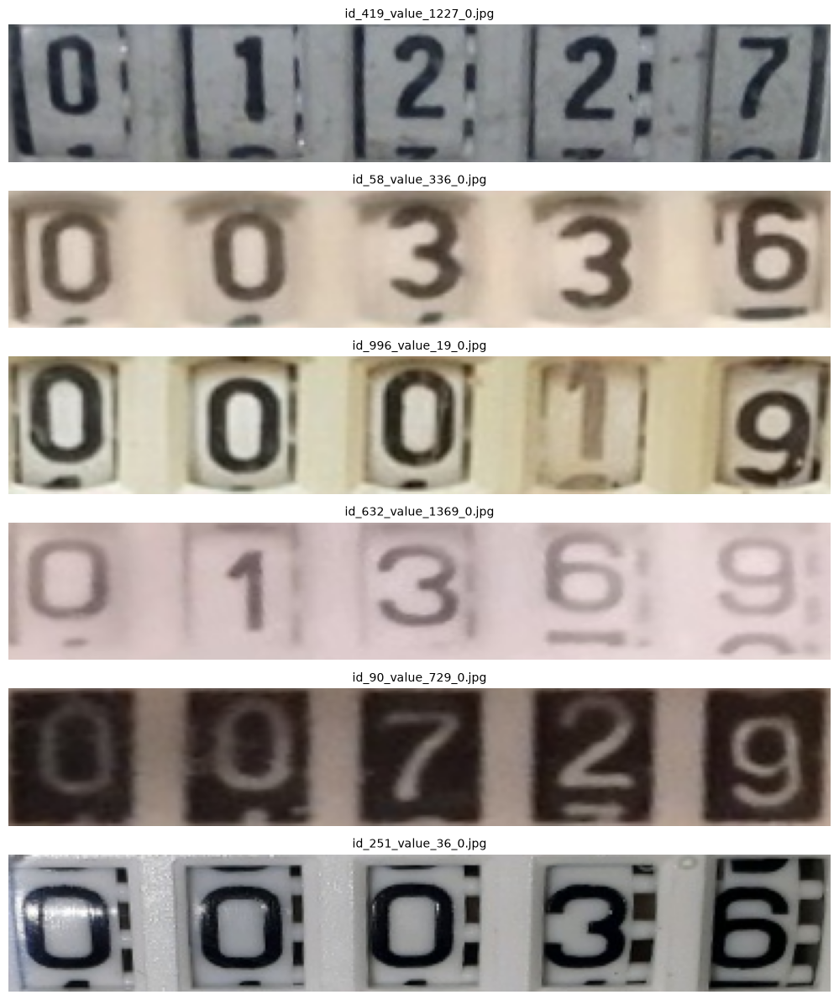

Imagens examinadas: 6


In [46]:
# Parte 3 - Inspeção de imagens com decimal zero

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Inclui o caso já conhecido e mais cinco exemplos
nomes_amostra = ["id_419_value_1227_0.jpg"]

outros = casos_zero.loc[
    casos_zero["photo_name"] != nomes_amostra[0],
    "photo_name"
].head(5).tolist()

nomes_amostra.extend(outros)

fig, axes = plt.subplots(6, 1, figsize=(12, 12))

for ax, nome in zip(axes, nomes_amostra):

    linha = df_validos[
        df_validos["photo_name"] == nome
    ].iloc[0]

    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    if imagem is None:
        print("Imagem não encontrada:", nome)
        ax.axis("off")
        continue

    imagem_rgb = cv2.cvtColor(
        imagem, cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    faixa = retificar_visor(imagem_rgb, pontos)

    # Consulta correções já validadas
    registro = controle_orientacao[
        controle_orientacao["photo_name"] == nome
    ]

    if (
        not registro.empty
        and registro["rotacao_necessaria"].iloc[0] == 180
    ):
        faixa = cv2.rotate(faixa, cv2.ROTATE_180)

    ax.imshow(faixa)
    ax.set_title(nome, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Imagens examinadas:", len(nomes_amostra))

In [47]:
# Parte 3 - Identificação dos casos com decimal zero

from pathlib import Path
import pandas as pd

# Recupera os 36 registros identificados
casos_investigacao = casos_zero.copy()

# Cria colunas para registrar a inspeção visual
casos_investigacao["digitos_visiveis"] = pd.NA
casos_investigacao["situacao"] = "pendente"

# Registra apenas os seis casos que já inspecionamos
casos_inspecionados = [
    "id_419_value_1227_0.jpg",
    "id_58_value_336_0.jpg",
    "id_996_value_19_0.jpg",
    "id_632_value_1369_0.jpg",
    "id_90_value_729_0.jpg",
    "id_251_value_36_0.jpg"
]

mascara = casos_investigacao["photo_name"].isin(
    casos_inspecionados
)

casos_investigacao.loc[
    mascara, "digitos_visiveis"
] = 5

casos_investigacao.loc[
    mascara, "situacao"
] = "cinco_posicoes_aparentes"

# Mostra os resultados
print("Total de casos com decimal zero:", len(casos_investigacao))

print("Casos inspecionados:", mascara.sum())

print("Casos pendentes:", (~mascara).sum())

display(casos_investigacao.head(10))

Total de casos com decimal zero: 36
Casos inspecionados: 6
Casos pendentes: 30


,photo_name,value,digitos_visiveis,situacao
90,id_58_value_336_0.jpg,336.0,5,cinco_posicoes_aparentes
93,id_419_value_1227_0.jpg,1227.0,5,cinco_posicoes_aparentes
106,id_996_value_19_0.jpg,19.0,5,cinco_posicoes_aparentes
131,id_632_value_1369_0.jpg,1369.0,5,cinco_posicoes_aparentes
151,id_90_value_729_0.jpg,729.0,5,cinco_posicoes_aparentes
189,id_251_value_36_0.jpg,36.0,5,cinco_posicoes_aparentes
216,id_946_value_809_0.jpg,809.0,<NA>,pendente
239,id_647_value_1315_0.jpg,1315.0,<NA>,pendente
279,id_799_value_22_0.jpg,22.0,<NA>,pendente
342,id_986_value_748_0.jpg,748.0,<NA>,pendente


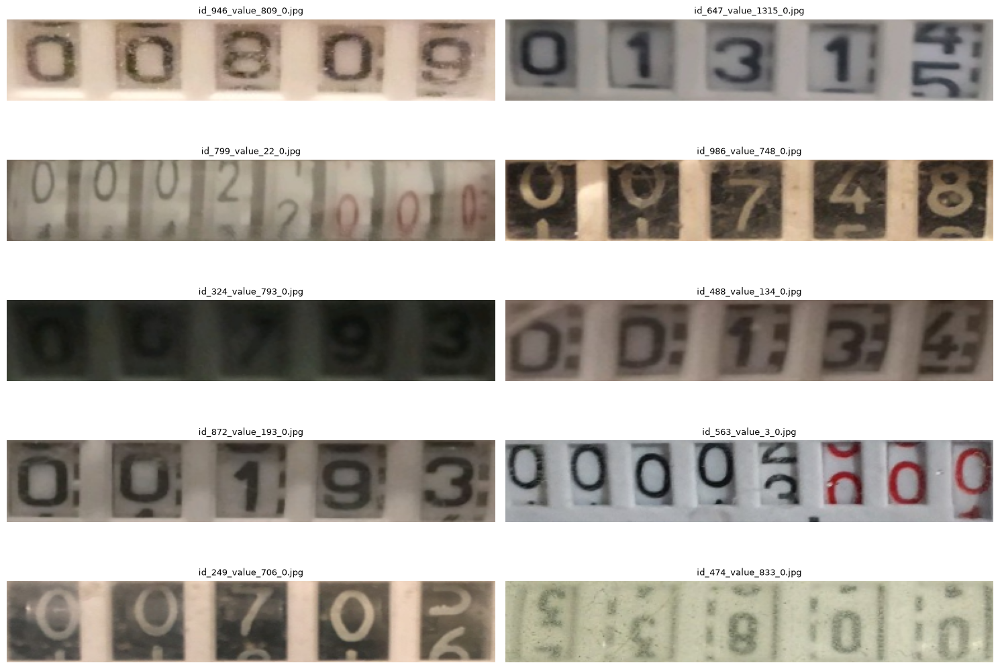

Imagens exibidas: 10


In [48]:
# Parte 3 - Inspeção dos próximos 10 casos com decimal zero

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona somente os casos ainda não inspecionados
pendentes_zero = casos_investigacao[
    casos_investigacao["situacao"] == "pendente"
]

# Seleciona os próximos dez
amostra_zero = pendentes_zero.head(10)

fig, axes = plt.subplots(5, 2, figsize=(15, 11))
axes = axes.flatten()

for ax, (_, registro) in zip(axes, amostra_zero.iterrows()):

    nome = registro["photo_name"]

    linha = df_validos[
        df_validos["photo_name"] == nome
    ].iloc[0]

    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    if imagem is None:
        ax.set_title(f"Arquivo não encontrado: {nome}")
        ax.axis("off")
        continue

    imagem_rgb = cv2.cvtColor(
        imagem, cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Aplica a retificação preliminar
    faixa = retificar_visor(imagem_rgb, pontos)

    # Não aplica rotação sem confirmação prévia
    ax.imshow(faixa)
    ax.set_title(nome, fontsize=9)
    ax.axis("off")

for ax in axes[len(amostra_zero):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Imagens exibidas:", len(amostra_zero))

In [49]:
# Parte 3 - Registro da segunda inspeção

cinco_posicoes = [
    "id_946_value_809_0.jpg",
    "id_647_value_1315_0.jpg",
    "id_986_value_748_0.jpg",
    "id_324_value_793_0.jpg",
    "id_488_value_134_0.jpg",
    "id_872_value_193_0.jpg",
    "id_249_value_706_0.jpg"
]

oito_posicoes = [
    "id_799_value_22_0.jpg",
    "id_563_value_3_0.jpg"
]

revisar = [
    "id_474_value_833_0.jpg"
]

# Registra cinco posições aparentes
mascara_cinco = casos_investigacao["photo_name"].isin(
    cinco_posicoes
)

casos_investigacao.loc[
    mascara_cinco, "digitos_visiveis"
] = 5

casos_investigacao.loc[
    mascara_cinco, "situacao"
] = "cinco_posicoes_aparentes"

# Registra oito posições aparentes
mascara_oito = casos_investigacao["photo_name"].isin(
    oito_posicoes
)

casos_investigacao.loc[
    mascara_oito, "digitos_visiveis"
] = 8

casos_investigacao.loc[
    mascara_oito, "situacao"
] = "oito_posicoes_aparentes"

# Mantém o caso invertido para revisão
mascara_revisar = casos_investigacao["photo_name"].isin(
    revisar
)

casos_investigacao.loc[
    mascara_revisar, "situacao"
] = "revisar_orientacao"

print("RESUMO DA INSPEÇÃO:")
print(casos_investigacao["situacao"].value_counts())

print("\nTOTAL DE REGISTROS:")
print(len(casos_investigacao))

RESUMO DA INSPEÇÃO:
situacao
pendente                    20
cinco_posicoes_aparentes    13
oito_posicoes_aparentes      2
revisar_orientacao           1
Name: count, dtype: int64

TOTAL DE REGISTROS:
36


In [50]:
# Parte 3 - Salvar a investigação dos casos com decimal zero

from pathlib import Path

# Define onde o arquivo será salvo
caminho_investigacao = Path(
    "data/controle/investigacao_decimal_zero.csv"
)

# Salva a tabela
casos_investigacao.to_csv(
    caminho_investigacao,
    index=False,
    encoding="utf-8"
)

# Confirma a gravação
print("Arquivo salvo com sucesso!")
print("Localização:", caminho_investigacao.resolve())
print("Total de registros:", len(casos_investigacao))

print("\nResumo:")
print(casos_investigacao["situacao"].value_counts())

Arquivo salvo com sucesso!
Localização: C:\Users\Arnóbio\OneDrive\Desktop\CESAR SCHOOL\Visão Computacional\Pratica_2_Hidrometros\vc-20262-p2\data\controle\investigacao_decimal_zero.csv
Total de registros: 36

Resumo:
situacao
pendente                    20
cinco_posicoes_aparentes    13
oito_posicoes_aparentes      2
revisar_orientacao           1
Name: count, dtype: int64


In [51]:
# Parte 3 - Próximo lote de inspeção

import pandas as pd

# Recupera o controle salvo
casos_investigacao = pd.read_csv(
    "data/controle/investigacao_decimal_zero.csv"
)

# Seleciona somente os registros pendentes
proximos_casos = casos_investigacao[
    casos_investigacao["situacao"] == "pendente"
].head(10)

print("PRÓXIMAS IMAGENS PARA INSPEÇÃO:")
display(proximos_casos[["photo_name", "value"]])

print("\nQuantidade selecionada:", len(proximos_casos))

PRÓXIMAS IMAGENS PARA INSPEÇÃO:


,photo_name,value
16,id_478_value_226_0.jpg,226.0
17,id_1237_value_454_0.jpg,454.0
18,id_509_value_156_0.jpg,156.0
19,id_258_value_619_0.jpg,619.0
20,id_566_value_258_0.jpg,258.0
21,id_860_value_2693_0.jpg,2693.0
22,id_96_value_353_0.jpg,353.0
23,id_1125_value_0_0.jpg,0.0
24,id_415_value_262_0.jpg,262.0
25,id_234_value_501_0.jpg,501.0



Quantidade selecionada: 10


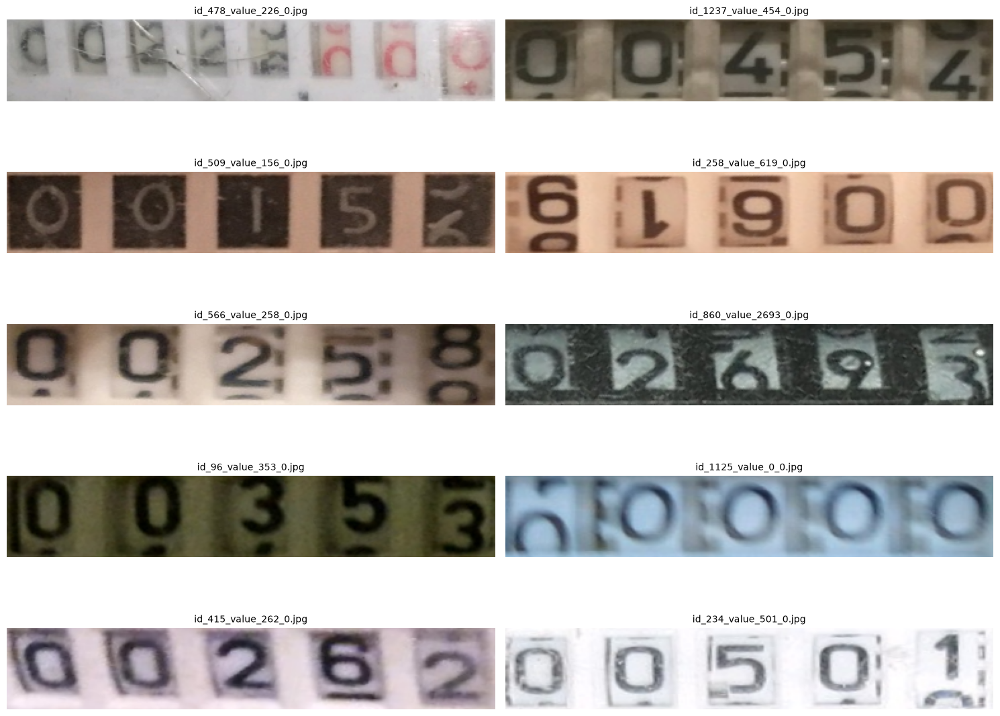

Quantidade de imagens exibidas: 10


In [52]:
# Parte 3 - Galeria do próximo lote de investigação

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(5, 2, figsize=(15, 12))
axes = axes.flatten()

for ax, (_, registro) in zip(axes, proximos_casos.iterrows()):

    nome = registro["photo_name"]

    # Localiza a anotação correspondente
    linha = df_validos[
        df_validos["photo_name"] == nome
    ].iloc[0]

    # Abre a fotografia
    caminho = Path("data/WaterMeters/images") / nome
    imagem = cv2.imread(str(caminho))

    if imagem is None:
        ax.set_title(f"Imagem não encontrada: {nome}")
        ax.axis("off")
        continue

    imagem_rgb = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    # Recupera o polígono
    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Aplica a retificação preliminar
    faixa = retificar_visor(imagem_rgb, pontos)

    # Exibe a faixa sem alterar a orientação
    ax.imshow(faixa)
    ax.set_title(nome, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Quantidade de imagens exibidas:", len(proximos_casos))

In [54]:
# Parte 3 - Registro da terceira inspeção

cinco_posicoes = [
    "id_1237_value_454_0.jpg",
    "id_509_value_156_0.jpg",
    "id_258_value_619_0.jpg",
    "id_566_value_258_0.jpg",
    "id_860_value_2693_0.jpg",
    "id_96_value_353_0.jpg",
    "id_1125_value_0_0.jpg",
    "id_415_value_262_0.jpg",
    "id_234_value_501_0.jpg"
]

oito_posicoes = [
    "id_478_value_226_0.jpg"
]

# Atualiza os casos com cinco posições aparentes
mascara_cinco = casos_investigacao[
    "photo_name"
].isin(cinco_posicoes)

casos_investigacao.loc[
    mascara_cinco, "digitos_visiveis"
] = 5

casos_investigacao.loc[
    mascara_cinco, "situacao"
] = "cinco_posicoes_aparentes"

# Atualiza o caso com oito posições aparentes
mascara_oito = casos_investigacao[
    "photo_name"
].isin(oito_posicoes)

casos_investigacao.loc[
    mascara_oito, "digitos_visiveis"
] = 8

casos_investigacao.loc[
    mascara_oito, "situacao"
] = "oito_posicoes_aparentes"

# Registra a necessidade de conferir a rotação
casos_investigacao["revisar_rotacao"] = (
    casos_investigacao["photo_name"]
    == "id_258_value_619_0.jpg"
)

print("RESUMO ATUALIZADO:")
print(casos_investigacao["situacao"].value_counts())

print("\nTOTAL DE REGISTROS:")
print(len(casos_investigacao)) 

RESUMO ATUALIZADO:
situacao
cinco_posicoes_aparentes    22
pendente                    10
oito_posicoes_aparentes      3
revisar_orientacao           1
Name: count, dtype: int64

TOTAL DE REGISTROS:
36


In [55]:
# Parte 3 - Salvar o progresso da investigação

from pathlib import Path

caminho = Path(
    "data/controle/investigacao_decimal_zero.csv"
)

casos_investigacao.to_csv(
    caminho,
    index=False,
    encoding="utf-8"
)

print("Controle atualizado com sucesso!")
print("Total de registros:", len(casos_investigacao))
print("Casos pendentes:",
      (casos_investigacao["situacao"] == "pendente").sum())

Controle atualizado com sucesso!
Total de registros: 36
Casos pendentes: 10


In [56]:
# Parte 3 - Identificação dos últimos casos pendentes

import pandas as pd

# Recupera a investigação salva
casos_investigacao = pd.read_csv(
    "data/controle/investigacao_decimal_zero.csv"
)

# Seleciona os registros ainda pendentes
ultimos_casos = casos_investigacao[
    casos_investigacao["situacao"] == "pendente"
].copy()

print("ÚLTIMAS IMAGENS PENDENTES:")
display(ultimos_casos[["photo_name", "value"]])

print("\nQuantidade de imagens pendentes:")
print(len(ultimos_casos))

ÚLTIMAS IMAGENS PENDENTES:


,photo_name,value
26,id_839_value_1025_0.jpg,1025.0
27,id_45_value_215_0.jpg,215.0
28,id_1011_value_567_0.jpg,567.0
29,id_494_value_854_0.jpg,854.0
30,id_874_value_509_0.jpg,509.0
31,id_77_value_665_0.jpg,665.0
32,id_630_value_164_0.jpg,164.0
33,id_1234_value_850_0.jpg,850.0
34,id_823_value_797_0.jpg,797.0
35,id_1121_value_712_0.jpg,712.0



Quantidade de imagens pendentes:
10


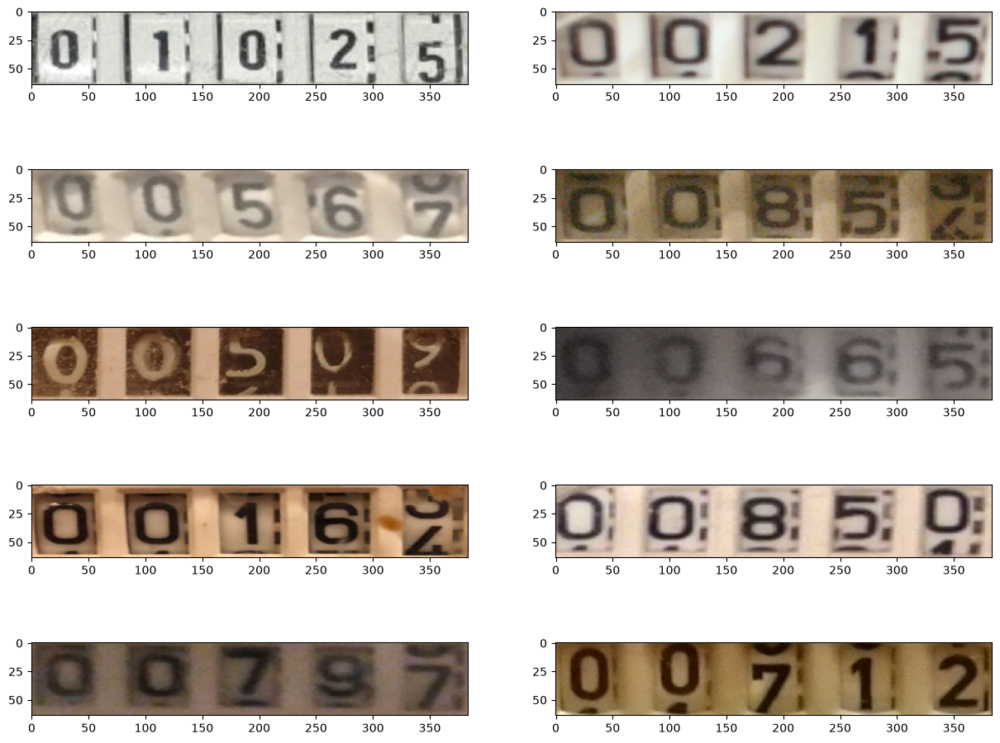

In [57]:
# Parte 3 - Inspeção visual dos últimos dez casos

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(5, 2, figsize=(15, 12))
axes = axes.flatten()

for ax, (_, registro) in zip(axes, ultimos_casos.iterrows()):

    nome = registro["photo_name"]

    # Localiza a anotação da fotografia
    linha = df_validos[
        df_validos["photo_name"] == nome
    ].iloc[0]

    # Abre a imagem original
    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    if imagem is None:
        ax.set_title(f"Imagem não encontrada: {nome}")
        ax.axis("off")
        continue

    # Converte as cores para RGB
    imagem_rgb = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    # Recupera o polígono anotado
    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Aplica a retificação experimental
    faixa = retificar_visor(imagem_rgb, pontos)

    # Exibe sem aplicar rotação automática
    ax.imshow(faixa)
    ax.set_title

In [58]:
# Parte 3 - Registro dos últimos dez casos examinados

cinco_posicoes_ultimo_lote = [
    "id_839_value_1025_0.jpg",
    "id_45_value_215_0.jpg",
    "id_1011_value_567_0.jpg",
    "id_494_value_854_0.jpg",
    "id_874_value_509_0.jpg",
    "id_77_value_665_0.jpg",
    "id_630_value_164_0.jpg",
    "id_1234_value_850_0.jpg",
    "id_823_value_797_0.jpg",
    "id_1121_value_712_0.jpg"
]

# Identifica as imagens do último lote
mascara = casos_investigacao["photo_name"].isin(
    cinco_posicoes_ultimo_lote
)

# Registra a observação preliminar
casos_investigacao.loc[
    mascara, "digitos_visiveis"
] = 5

casos_investigacao.loc[
    mascara, "situacao"
] = "cinco_posicoes_aparentes"

# Salva o controle atualizado
casos_investigacao.to_csv(
    "data/controle/investigacao_decimal_zero.csv",
    index=False
)

print("RESUMO FINAL DA INSPEÇÃO PRELIMINAR:")
print(casos_investigacao["situacao"].value_counts())

print("\nCasos pendentes:")
print((casos_investigacao["situacao"] == "pendente").sum())

print("\nTotal de registros:")
print(len(casos_investigacao))

RESUMO FINAL DA INSPEÇÃO PRELIMINAR:
situacao
cinco_posicoes_aparentes    32
oito_posicoes_aparentes      3
revisar_orientacao           1
Name: count, dtype: int64

Casos pendentes:
0

Total de registros:
36


In [59]:
# Parte 3 - Consolidação da investigação preliminar

import pandas as pd

casos_investigacao = pd.read_csv(
    "data/controle/investigacao_decimal_zero.csv"
)

print("Total de casos:", len(casos_investigacao))

print("\nDistribuição das situações:")
print(casos_investigacao["situacao"].value_counts())

print("\nCasos que ainda exigem revisão:")
display(
    casos_investigacao[
        casos_investigacao["situacao"] == "revisar_orientacao"
    ][["photo_name", "value", "situacao"]]
)

Total de casos: 36

Distribuição das situações:
situacao
cinco_posicoes_aparentes    32
oito_posicoes_aparentes      3
revisar_orientacao           1
Name: count, dtype: int64

Casos que ainda exigem revisão:


,photo_name,value,situacao
15,id_474_value_833_0.jpg,833.0,revisar_orientacao


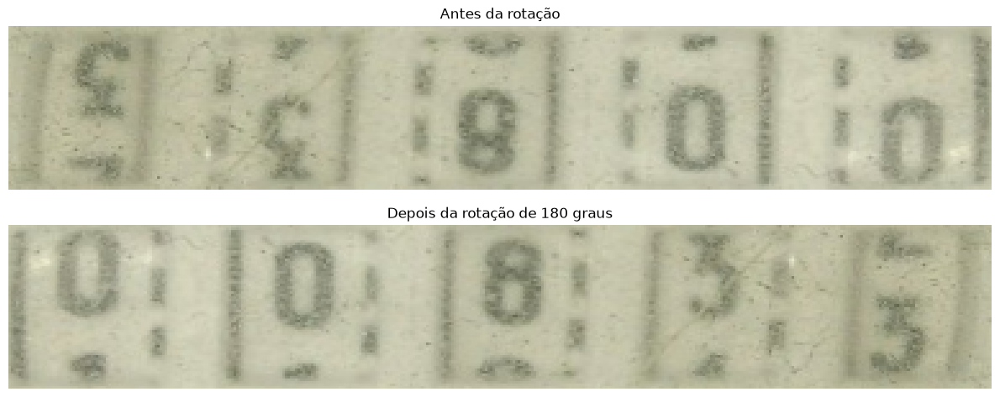

Leitura esperada: 00833,000
Dimensões: (64, 384, 3)


In [61]:
# Parte 3 - Revisão da orientação da imagem id_474

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

nome = "id_474_value_833_0.jpg"

# Localiza a anotação
linha = df_validos[
    df_validos["photo_name"] == nome
].iloc[0]

# Abre a fotografia original
caminho = Path("data/WaterMeters/images") / nome

imagem = cv2.imread(str(caminho))
imagem_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

altura, largura = imagem_rgb.shape[:2]

# Recupera as coordenadas do polígono
anotacao = ast.literal_eval(linha["location"])

pontos = np.array([
    [p["x"] * largura, p["y"] * altura]
    for p in anotacao["data"]
], dtype=np.float32)

# Retificação preliminar
faixa_original = retificar_visor(imagem_rgb, pontos)

# Teste de rotação em 180 graus
faixa_rotacionada = cv2.rotate(
    faixa_original,
    cv2.ROTATE_180
)

# Compara antes e depois
fig, axes = plt.subplots(2, 1, figsize=(12, 5))

axes[0].imshow(faixa_original)
axes[0].set_title("Antes da rotação")
axes[0].axis("off")

axes[1].imshow(faixa_rotacionada)
axes[1].set_title("Depois da rotação de 180 graus")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Leitura esperada: 00833,000")
print("Dimensões:", faixa_rotacionada.shape)

In [62]:
# Parte 3 - Atualização da investigação da imagem id_474

nome = "id_474_value_833_0.jpg"

mascara = casos_investigacao["photo_name"] == nome

# Registra as cinco posições aparentes
casos_investigacao.loc[
    mascara, "digitos_visiveis"
] = 5

casos_investigacao.loc[
    mascara, "situacao"
] = "cinco_posicoes_aparentes"

# Registra a correção de orientação separadamente
casos_investigacao.loc[
    mascara, "rotacao_confirmada"
] = 180

# Salva os resultados
casos_investigacao.to_csv(
    "data/controle/investigacao_decimal_zero.csv",
    index=False
)

print("RESUMO DA INVESTIGAÇÃO:")
print(casos_investigacao["situacao"].value_counts())

print("\nTotal de imagens:")
print(len(casos_investigacao))

print("\nRegistro da imagem revisada:")
display(casos_investigacao.loc[mascara])

RESUMO DA INVESTIGAÇÃO:
situacao
cinco_posicoes_aparentes    33
oito_posicoes_aparentes      3
Name: count, dtype: int64

Total de imagens:
36

Registro da imagem revisada:


,photo_name,value,digitos_visiveis,situacao,revisar_rotacao,rotacao_confirmada
15,id_474_value_833_0.jpg,833.0,5.0,cinco_posicoes_aparentes,False,180.0


In [63]:
# Parte 3 - Atualização do controle principal de orientação

import pandas as pd

caminho = "data/controle/controle_orientacao.csv"

controle_orientacao = pd.read_csv(caminho)

# Imagem cuja rotação foi confirmada
nome = "id_474_value_833_0.jpg"

mascara = controle_orientacao["photo_name"] == nome

# Registra a orientação validada
controle_orientacao.loc[
    mascara, "orientacao_validada"
] = True

# Registra a necessidade de rotação
controle_orientacao.loc[
    mascara, "rotacao_necessaria"
] = 180

# Salva o arquivo atualizado
controle_orientacao.to_csv(
    caminho,
    index=False
)

print("Orientações validadas:",
      controle_orientacao["orientacao_validada"].sum())

print("Rotações de 180 graus registradas:",
      (controle_orientacao["rotacao_necessaria"] == 180).sum())

print("Orientações pendentes:",
      (~controle_orientacao["orientacao_validada"]).sum())

Orientações validadas: 13
Rotações de 180 graus registradas: 8
Orientações pendentes: 1230


In [64]:
# Parte 3 - Retificação geométrica: versão 2

import cv2
import numpy as np

def retificar_visor_v2(imagem_rgb, pontos, largura=384, altura=64):

    # Garante que as coordenadas estejam no formato correto
    pontos = np.asarray(pontos, dtype=np.float32)

    if pontos.ndim != 2 or pontos.shape[1] != 2:
        raise ValueError("Os pontos devem ter formato (N, 2).")

    if len(pontos) < 4:
        raise ValueError("O polígono deve possuir pelo menos 4 pontos.")

    # Calcula o menor retângulo rotacionado que contém o polígono
    retangulo = cv2.minAreaRect(pontos)

    # Obtém os quatro cantos desse retângulo
    cantos = cv2.boxPoints(retangulo).astype(np.float32)

    # Identifica o lado mais comprido
    lados = np.roll(cantos, -1, axis=0) - cantos

    comprimentos = np.linalg.norm(lados, axis=1)

    indice_lado_maior = int(np.argmax(comprimentos))

    # Organiza os cantos começando pelo lado maior
    origem = np.roll(
        cantos,
        -indice_lado_maior,
        axis=0
    ).astype(np.float32)

    # Coordenadas da faixa horizontal desejada
    destino = np.array([
        [0, 0],
        [largura - 1, 0],
        [largura - 1, altura - 1],
        [0, altura - 1]
    ], dtype=np.float32)

    # Calcula a transformação geométrica
    matriz = cv2.getPerspectiveTransform(origem, destino)

    # Aplica a transformação
    faixa = cv2.warpPerspective(
        imagem_rgb,
        matriz,
        (largura, altura),
        flags=cv2.INTER_LINEAR
    )

    return faixa

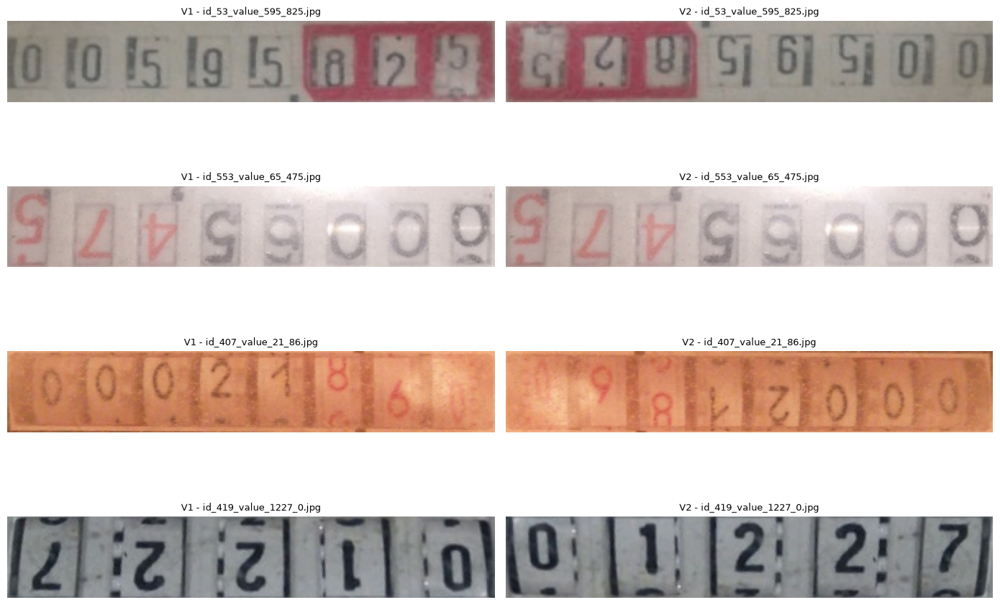

Comparação concluída!


In [65]:
# Parte 3 - Comparação entre os métodos de retificação

import ast
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

nomes_teste = [
    "id_53_value_595_825.jpg",
    "id_553_value_65_475.jpg",
    "id_407_value_21_86.jpg",
    "id_419_value_1227_0.jpg"
]

fig, axes = plt.subplots(
    len(nomes_teste),
    2,
    figsize=(14, 10)
)

for i, nome in enumerate(nomes_teste):

    linha = df_validos[
        df_validos["photo_name"] == nome
    ].iloc[0]

    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    if imagem is None:
        raise FileNotFoundError(caminho)

    imagem_rgb = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Versão experimental anterior
    faixa_v1 = retificar_visor(imagem_rgb, pontos)

    # Nova versão experimental
    faixa_v2 = retificar_visor_v2(imagem_rgb, pontos)

    axes[i, 0].imshow(faixa_v1)
    axes[i, 0].set_title(f"V1 - {nome}", fontsize=9)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(faixa_v2)
    axes[i, 1].set_title(f"V2 - {nome}", fontsize=9)
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

print("Comparação concluída!")

In [66]:
# Parte 3 - Análise da proporção geométrica dos visores

import ast
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

resultados_geometria = []

for _, linha in df_validos.iterrows():

    nome = linha["photo_name"]
    caminho = Path("data/WaterMeters/images") / nome

    with Image.open(caminho) as imagem:
        largura_img, altura_img = imagem.size

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura_img, p["y"] * altura_img]
        for p in anotacao["data"]
    ], dtype=np.float32)

    retangulo = cv2.minAreaRect(pontos)

    largura_ret, altura_ret = retangulo[1]

    lado_maior = max(largura_ret, altura_ret)
    lado_menor = min(largura_ret, altura_ret)

    proporcao = (
        lado_maior / lado_menor
        if lado_menor > 0
        else np.nan
    )

    resultados_geometria.append({
        "photo_name": nome,
        "n_pontos": len(pontos),
        "proporcao": proporcao
    })

df_geometria = pd.DataFrame(resultados_geometria)

print("ESTATÍSTICAS DA PROPORÇÃO GEOMÉTRICA:")
print(df_geometria["proporcao"].describe())

print("\nTOTAL DE IMAGENS:")
print(len(df_geometria))

print("\nPROPORÇÃO POR QUANTIDADE DE VÉRTICES:")
display(
    df_geometria.groupby("n_pontos")["proporcao"].describe()
)

ESTATÍSTICAS DA PROPORÇÃO GEOMÉTRICA:
count    1243.000000
mean        6.318561
std         3.277654
min         2.626919
25%         4.462832
50%         5.326666
75%         6.720798
max        30.290045
Name: proporcao, dtype: float64

TOTAL DE IMAGENS:
1243

PROPORÇÃO POR QUANTIDADE DE VÉRTICES:


,count,mean,std,min,25%,50%,75%,max
n_pontos,,,,,,,,
4,505.0,6.070220,2.998166,3.606932,4.282641,4.540245,7.015895,30.290045
6,508.0,6.725196,3.485309,2.626919,5.115005,5.583204,6.289542,28.816597
8,230.0,5.965699,3.310608,2.833597,4.422021,4.997840,5.530708,23.709710


In [67]:
# Parte 3 - Identificação de proporções geométricas extremas

print("CINCO MENORES PROPORÇÕES:")
display(
    df_geometria.nsmallest(
        5, "proporcao"
    )
)

print("\nCINCO MAIORES PROPORÇÕES:")
display(
    df_geometria.nlargest(
        5, "proporcao"
    )
)

CINCO MENORES PROPORÇÕES:


,photo_name,n_pontos,proporcao
442,id_1065_value_151_704.jpg,6,2.626919
734,id_62_value_367_401.jpg,6,2.789011
315,id_306_value_158_719.jpg,8,2.833597
1092,id_472_value_179_428.jpg,8,2.997280
564,id_554_value_727_113.jpg,6,3.050250



CINCO MAIORES PROPORÇÕES:


,photo_name,n_pontos,proporcao
700,id_236_value_136_123.jpg,4,30.290045
764,id_43_value_123_689.jpg,6,28.816597
227,id_185_value_177_586.jpg,6,24.318891
690,id_623_value_445_282.jpg,6,24.307264
627,id_563_value_3_0.jpg,6,23.961869


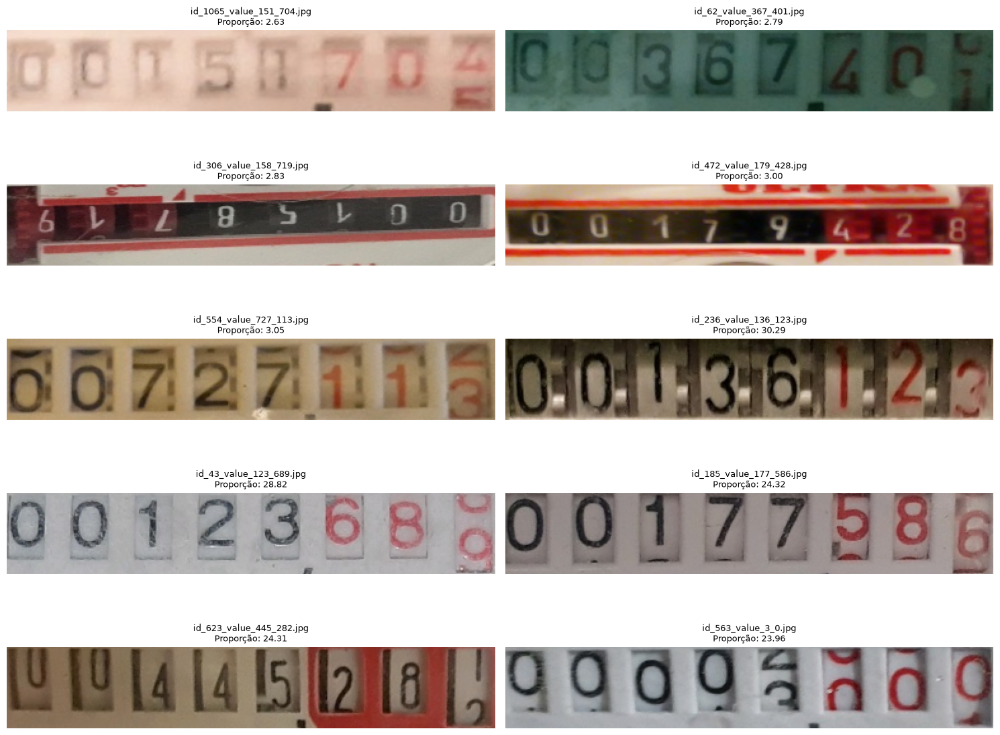

In [68]:
# Parte 3 - Inspeção de proporções geométricas extremas

import ast
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Seleciona as imagens com proporções extremas
menores = df_geometria.nsmallest(5, "proporcao")
maiores = df_geometria.nlargest(5, "proporcao")

amostra_extremos = pd.concat([menores, maiores])

fig, axes = plt.subplots(5, 2, figsize=(15, 12))
axes = axes.flatten()

for ax, (_, registro) in zip(
    axes, amostra_extremos.iterrows()
):
    nome = registro["photo_name"]

    linha = df_validos[
        df_validos["photo_name"] == nome
    ].iloc[0]

    caminho = Path("data/WaterMeters/images") / nome

    imagem = cv2.imread(str(caminho))

    if imagem is None:
        ax.set_title(f"Não encontrada: {nome}")
        ax.axis("off")
        continue

    imagem_rgb = cv2.cvtColor(
        imagem, cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Retificação experimental V1
    faixa = retificar_visor(imagem_rgb, pontos)

    ax.imshow(faixa)
    ax.set_title(
        f"{nome}\nProporção: {registro['proporcao']:.2f}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [69]:
# Parte 3 - Salvar estatísticas geométricas

from pathlib import Path

caminho_geometria = Path(
    "data/controle/geometria_visores.csv"
)

df_geometria.to_csv(
    caminho_geometria,
    index=False,
    encoding="utf-8"
)

print("Estatísticas geométricas salvas!")
print("Total de registros:", len(df_geometria))
print("Arquivo:", caminho_geometria.resolve())

Estatísticas geométricas salvas!
Total de registros: 1243
Arquivo: C:\Users\Arnóbio\OneDrive\Desktop\CESAR SCHOOL\Visão Computacional\Pratica_2_Hidrometros\vc-20262-p2\data\controle\geometria_visores.csv


In [4]:
# Parte 3 - Padronização dos rótulos em 8 dígitos

import re

def extrair_rotulo(nome_arquivo):

    padrao = r"id_\d+_value_(\d+)_(\d+)\.jpg"
    
    resultado = re.fullmatch(padrao, nome_arquivo)

    if resultado is None:
        return None

    parte_inteira = resultado.group(1)
    parte_decimal = resultado.group(2)

    # Não aceita mais de 5 dígitos inteiros
    if len(parte_inteira) > 5:
        return None

    # Não aceita mais de 3 dígitos decimais
    if len(parte_decimal) > 3:
        return None

    # Completa a parte inteira com zeros à esquerda
    inteiros = parte_inteira.zfill(5)

    # Completa a parte decimal com zeros à direita
    decimais = parte_decimal.ljust(3, "0")

    rotulo = inteiros + decimais

    return rotulo


# Testa com exemplos conhecidos
exemplos_teste = [
    "id_53_value_595_825.jpg",
    "id_407_value_21_86.jpg",
    "id_419_value_1227_0.jpg",
    "id_664_value_45_2676.jpg"
]

for nome in exemplos_teste:
    print(nome, "->", extrair_rotulo(nome))

id_53_value_595_825.jpg -> 00595825
id_407_value_21_86.jpg -> 00021860
id_419_value_1227_0.jpg -> 01227000
id_664_value_45_2676.jpg -> None


In [5]:
# Parte 3 - Validação dos rótulos de todo o dataset

# Cria uma cópia da tabela original
df_rotulos = df.copy()

# Aplica a função a todas as fotografias
df_rotulos["rotulo_8digitos"] = (
    df_rotulos["photo_name"].apply(extrair_rotulo)
)

# Identifica quais rótulos atendem ao formato
df_rotulos["formato_valido"] = (
    df_rotulos["rotulo_8digitos"].notna()
)

print("TOTAL DE IMAGENS:")
print(len(df_rotulos))

print("\nRÓTULOS COM FORMATO VÁLIDO:")
print(df_rotulos["formato_valido"].sum())

print("\nRÓTULOS REJEITADOS:")
print((~df_rotulos["formato_valido"]).sum())

print("\nIMAGENS REJEITADAS:")
display(
    df_rotulos.loc[
        ~df_rotulos["formato_valido"],
        ["photo_name", "value"]
    ]
)

# Compara os rótulos válidos com o split oficial
nomes_validos = set(
    df_rotulos.loc[
        df_rotulos["formato_valido"],
        "photo_name"
    ]
)

nomes_split = set(splits["photo_name"])

print("\nRÓTULOS VÁLIDOS COINCIDEM COM O SPLIT OFICIAL:")
print(nomes_validos == nomes_split)

TOTAL DE IMAGENS:
1244

RÓTULOS COM FORMATO VÁLIDO:
1243

RÓTULOS REJEITADOS:
1

IMAGENS REJEITADAS:


,photo_name,value
454,id_664_value_45_2676.jpg,45.2676



RÓTULOS VÁLIDOS COINCIDEM COM O SPLIT OFICIAL:
True


TOTAL DE RÓTULOS DE DÍGITOS:
9944

DISTRIBUIÇÃO DAS CLASSES:


,digit,frequencia,percentual
0,0,3549,35.689863
1,1,1003,10.086484
2,2,777,7.813757
3,3,779,7.833870
4,4,698,7.019308
5,5,677,6.808126
6,6,638,6.415929
7,7,620,6.234916
8,8,613,6.164521
9,9,590,5.933226



CLASSE MAJORITÁRIA:
0


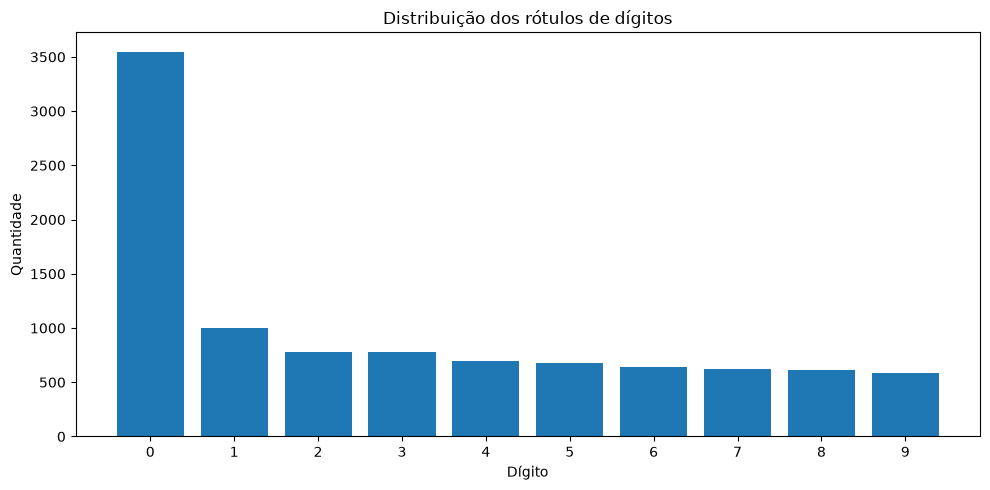

In [72]:
# Parte 2 - Distribuição dos rótulos de dígitos

import pandas as pd
import matplotlib.pyplot as plt

# Seleciona somente as imagens válidas
dados_validos = df_rotulos[
    df_rotulos["formato_valido"]
].copy()

# Junta todos os rótulos de oito dígitos
todos_digitos = "".join(
    dados_validos["rotulo_8digitos"].tolist()
)

# Conta a frequência de cada classe
frequencias = pd.Series(
    list(todos_digitos)
).value_counts().reindex(
    list("0123456789"),
    fill_value=0
)

percentuais = frequencias / frequencias.sum() * 100

distribuicao = pd.DataFrame({
    "digit": frequencias.index,
    "frequencia": frequencias.values,
    "percentual": percentuais.values
})

print("TOTAL DE RÓTULOS DE DÍGITOS:")
print(frequencias.sum())

print("\nDISTRIBUIÇÃO DAS CLASSES:")
display(distribuicao)

print("\nCLASSE MAJORITÁRIA:")
print(frequencias.idxmax())

# Gráfico
plt.figure(figsize=(10, 5))
plt.bar(distribuicao["digit"], distribuicao["frequencia"])
plt.xlabel("Dígito")
plt.ylabel("Quantidade")
plt.title("Distribuição dos rótulos de dígitos")
plt.tight_layout()
plt.show()

FREQUÊNCIA DOS DÍGITOS POR POSIÇÃO:


,0,1,2,3,4,5,6,7
rotulo_8digitos,,,,,,,,
0,1240,1192,393,146,129,154,167,128
1,1,41,282,133,134,134,135,143
2,0,7,176,130,119,115,112,118
3,0,0,126,141,133,139,117,123
4,1,0,81,136,103,140,108,129
5,0,1,59,123,129,121,125,119
6,0,1,48,123,112,115,120,119
7,0,0,38,106,113,106,126,131
8,0,0,22,92,138,129,127,105



PERCENTUAL DE ZEROS POR POSIÇÃO:
0    99.76
1    95.90
2    31.62
3    11.75
4    10.38
5    12.39
6    13.44
7    10.30
Name: 0, dtype: float64


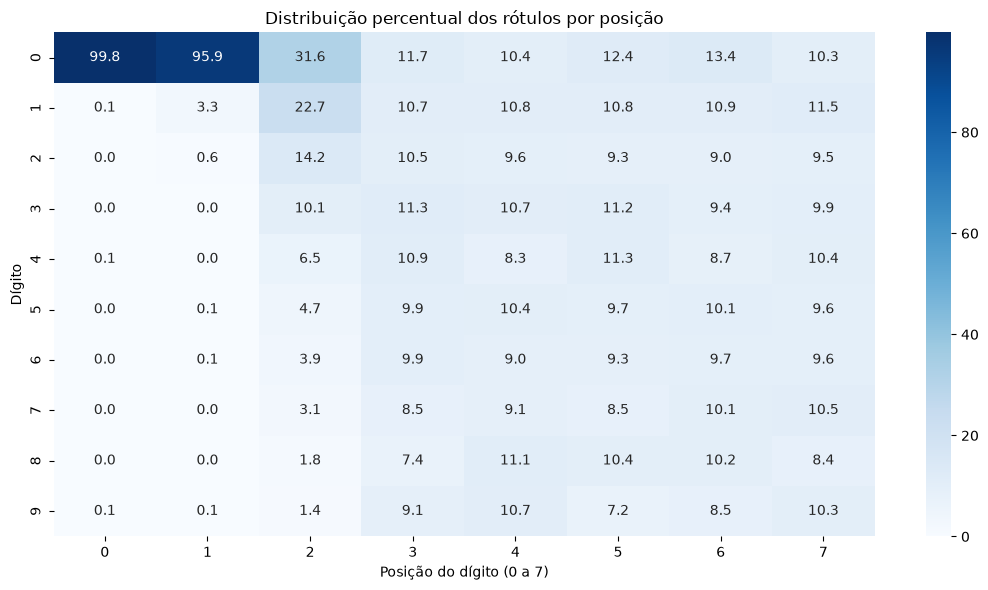

In [73]:
# Parte 2 - Distribuição dos dígitos por posição

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Utiliza as leituras com formato válido
rotulos = dados_validos["rotulo_8digitos"]

# Conta a frequência de cada dígito em cada posição
matriz = pd.DataFrame(
    {
        posicao: rotulos.str[posicao].value_counts()
        for posicao in range(8)
    }
).reindex(
    list("0123456789"),
    fill_value=0
).fillna(0).astype(int)

# Calcula percentuais em cada posição
matriz_percentual = matriz.div(
    matriz.sum(axis=0),
    axis=1
) * 100

print("FREQUÊNCIA DOS DÍGITOS POR POSIÇÃO:")
display(matriz)

print("\nPERCENTUAL DE ZEROS POR POSIÇÃO:")
print(matriz_percentual.loc["0"].round(2))

# Gráfico de calor
plt.figure(figsize=(11, 6))

sns.heatmap(
    matriz_percentual,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.xlabel("Posição do dígito (0 a 7)")
plt.ylabel("Dígito")
plt.title("Distribuição percentual dos rótulos por posição")

plt.tight_layout()
plt.show()

In [74]:
# Parte 2 - Salvar a distribuição dos rótulos

from pathlib import Path

pasta_controle = Path("data/controle")
pasta_controle.mkdir(parents=True, exist_ok=True)

# Salva a distribuição geral
distribuicao.to_csv(
    pasta_controle / "distribuicao_digitos.csv",
    index=False
)

# Salva a distribuição percentual por posição
matriz_percentual.to_csv(
    pasta_controle / "distribuicao_por_posicao.csv"
)

print("Distribuições salvas com sucesso!")
print("Total de rótulos:", frequencias.sum())
print("Classe majoritária:", frequencias.idxmax())

Distribuições salvas com sucesso!
Total de rótulos: 9944
Classe majoritária: 0


In [6]:
# Parte 3 - Preparação do índice de imagens

import pandas as pd

# Seleciona apenas os rótulos com formato válido
base = df_rotulos.loc[
    df_rotulos["formato_valido"],
    ["photo_name", "location", "rotulo_8digitos"]
].copy()

# Incorpora a divisão oficial do professor
base = base.merge(
    splits[["photo_name", "split"]],
    on="photo_name",
    how="left",
    validate="one_to_one"
)

# Confere a integridade da tabela
assert len(base) == 1243
assert base["photo_name"].is_unique
assert base["split"].notna().all()
assert base["rotulo_8digitos"].str.len().eq(8).all()

print("Total de imagens:", len(base))

print("\nDistribuição oficial:")
print(base["split"].value_counts())

print("\nPrimeiras linhas:")
display(
    base[
        ["photo_name", "rotulo_8digitos", "split"]
    ].head()
)

print("\nVerificações concluídas com sucesso!")

Total de imagens: 1243

Distribuição oficial:
split
train    870
test     187
val      186
Name: count, dtype: int64

Primeiras linhas:


,photo_name,rotulo_8digitos,split
0,id_53_value_595_825.jpg,00595825,train
1,id_553_value_65_475.jpg,00065475,train
2,id_407_value_21_86.jpg,00021860,test
3,id_252_value_313_322.jpg,00313322,train
4,id_851_value_305_162.jpg,00305162,train



Verificações concluídas com sucesso!


In [76]:
# Parte 3 - Salvar a base de preparação

from pathlib import Path

caminho_base = Path("data/controle/base_preparacao.csv")

base.to_csv(
    caminho_base,
    index=False,
    encoding="utf-8"
)

print("Base de preparação salva com sucesso!")
print("Total de imagens:", len(base))
print("Total previsto de recortes:", len(base) * 8)
print("Arquivo:", caminho_base.resolve())

Base de preparação salva com sucesso!
Total de imagens: 1243
Total previsto de recortes: 9944
Arquivo: C:\Users\Arnóbio\OneDrive\Desktop\CESAR SCHOOL\Visão Computacional\Pratica_2_Hidrometros\vc-20262-p2\data\controle\base_preparacao.csv


In [9]:
# Parte 3 - Função de processamento preliminar

import ast
import cv2
import numpy as np
from pathlib import Path

def processar_imagem(linha):

    # Identifica a fotografia
    nome = linha["photo_name"]

    caminho = Path("data/WaterMeters/images") / nome

    # Abre a fotografia original
    imagem = cv2.imread(str(caminho))

    if imagem is None:
        raise FileNotFoundError(f"Imagem não encontrada: {nome}")

    # Converte BGR para RGB
    imagem_rgb = cv2.cvtColor(
        imagem, cv2.COLOR_BGR2RGB
    )

    altura, largura = imagem_rgb.shape[:2]

    # Recupera o polígono de anotação
    anotacao = ast.literal_eval(linha["location"])

    pontos = np.array([
        [p["x"] * largura, p["y"] * altura]
        for p in anotacao["data"]
    ], dtype=np.float32)

    # Produz a faixa preliminar
    faixa = retificar_visor(
        imagem_rgb,
        pontos
    )

    # Verifica as dimensões
    assert faixa.shape[:2] == (64, 384)

    return {
        "photo_name": nome,
        "faixa": faixa,
        "n_pontos": len(pontos),
        "rotulo": linha["rotulo_8digitos"],
        "split": linha["split"]
    }

In [10]:
print("Função processar_imagem disponível:",
      callable(processar_imagem))

Função processar_imagem disponível: True


Imagem: id_53_value_595_825.jpg
Rótulo: 00595825
Split: train
Pontos do polígono: 8
Dimensões: (64, 384, 3)


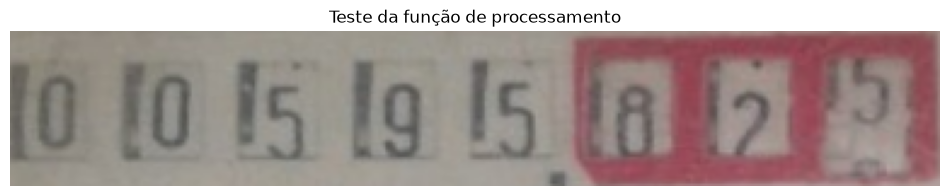

In [78]:
# Parte 3 - Teste da função de processamento

import matplotlib.pyplot as plt

# Seleciona a primeira fotografia da base
linha_teste = base.iloc[0]

resultado = processar_imagem(linha_teste)

print("Imagem:", resultado["photo_name"])
print("Rótulo:", resultado["rotulo"])
print("Split:", resultado["split"])
print("Pontos do polígono:", resultado["n_pontos"])
print("Dimensões:", resultado["faixa"].shape)

plt.figure(figsize=(12, 3))
plt.imshow(resultado["faixa"])
plt.title("Teste da função de processamento")
plt.axis("off")
plt.show()

In [79]:
# Parte 3 - Teste técnico do processamento completo

import pandas as pd
from tqdm.auto import tqdm

resultados_teste = []

for _, linha in tqdm(
    base.iterrows(),
    total=len(base),
    desc="Verificando imagens"
):

    nome = linha["photo_name"]

    try:
        # Processa uma imagem
        resultado = processar_imagem(linha)

        # Confere as dimensões
        dimensoes_corretas = (
            resultado["faixa"].shape == (64, 384, 3)
        )

        resultados_teste.append({
            "photo_name": nome,
            "sucesso": dimensoes_corretas,
            "erro": ""
        })

    except Exception as erro:

        resultados_teste.append({
            "photo_name": nome,
            "sucesso": False,
            "erro": str(erro)
        })

# Organiza os resultados em uma tabela
df_teste = pd.DataFrame(resultados_teste)

print("\nTOTAL DE IMAGENS:")
print(len(df_teste))

print("\nPROCESSADAS SEM ERRO:")
print(df_teste["sucesso"].sum())

print("\nFALHAS:")
print((~df_teste["sucesso"]).sum())

print("\nDETALHES DAS FALHAS:")
display(df_teste.loc[~df_teste["sucesso"]])

Verificando imagens:   0%|          | 0/1243 [00:00<?, ?it/s]


TOTAL DE IMAGENS:
1243

PROCESSADAS SEM ERRO:
1243

FALHAS:
0

DETALHES DAS FALHAS:


,photo_name,sucesso,erro


In [80]:
# Parte 3 - Salvar relatório de processamento

from pathlib import Path

caminho_relatorio = Path(
    "data/controle/relatorio_processamento.csv"
)

df_teste.to_csv(
    caminho_relatorio,
    index=False,
    encoding="utf-8"
)

print("Relatório salvo com sucesso!")
print("Total de imagens:", len(df_teste))
print("Imagens processadas:", df_teste["sucesso"].sum())
print("Falhas:", (~df_teste["sucesso"]).sum())

Relatório salvo com sucesso!
Total de imagens: 1243
Imagens processadas: 1243
Falhas: 0


In [81]:
# Parte 3 - Galeria paginada para auditoria das faixas

import matplotlib.pyplot as plt
import numpy as np
import cv2

def mostrar_lote_auditoria(base_dados, pagina=0, tamanho_lote=12):

    inicio = pagina * tamanho_lote
    fim = inicio + tamanho_lote

    lote = base_dados.iloc[inicio:fim]

    if lote.empty:
        print("Não existem imagens nesta página.")
        return

    fig, axes = plt.subplots(
        6, 2,
        figsize=(15, 13)
    )

    axes = axes.flatten()

    for ax, (_, linha) in zip(axes, lote.iterrows()):

        resultado = processar_imagem(linha)

        nome = resultado["photo_name"]
        faixa = resultado["faixa"]
        rotulo = resultado["rotulo"]

        ax.imshow(faixa)

        ax.set_title(
            f"{nome}\nRótulo: {rotulo}",
            fontsize=9
        )

        ax.axis("off")

    for ax in axes[len(lote):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Página:", pagina)
    print("Imagens exibidas:", len(lote))

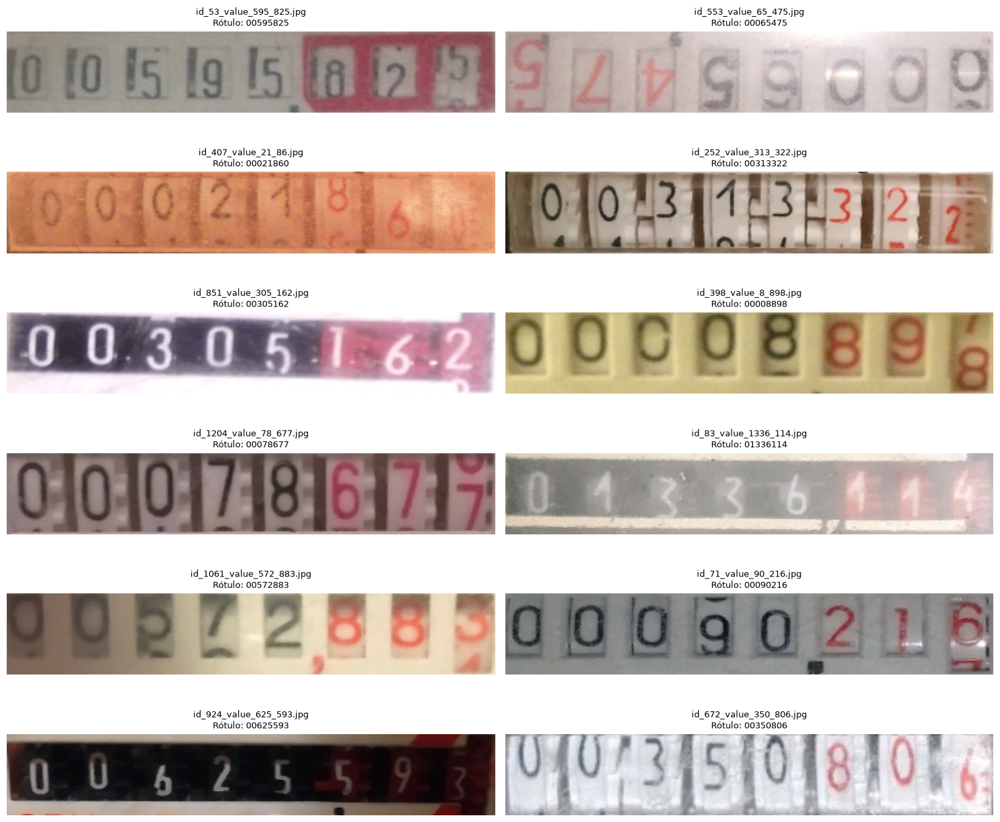

Página: 0
Imagens exibidas: 12


In [82]:
# Teste da galeria de auditoria

mostrar_lote_auditoria(
    base_dados=base,
    pagina=0,
    tamanho_lote=12
)

In [11]:
# Parte 3 - Aplicar correções de orientação já validadas

import pandas as pd
import cv2

# Recupera o controle de orientação salvo
controle = pd.read_csv(
    "data/controle/controle_orientacao.csv"
)

def aplicar_orientacao_validada(faixa, nome_imagem):

    registro = controle.loc[
        controle["photo_name"] == nome_imagem
    ]

    if registro.empty:
        raise ValueError(
            f"Imagem ausente do controle: {nome_imagem}"
        )

    linha = registro.iloc[0]

    # Não considera imagens pendentes como corrigidas
    if not bool(linha["orientacao_validada"]):
        return faixa, False

    rotacao = linha["rotacao_necessaria"]

    if rotacao == 180:
        faixa = cv2.rotate(faixa, cv2.ROTATE_180)

    elif rotacao != 0:
        raise ValueError(
            f"Rotação não reconhecida: {rotacao}"
        )

    return faixa, True

print("Função criada com sucesso!")
print("Orientações validadas:",
      controle["orientacao_validada"].sum())

Função criada com sucesso!
Orientações validadas: 25


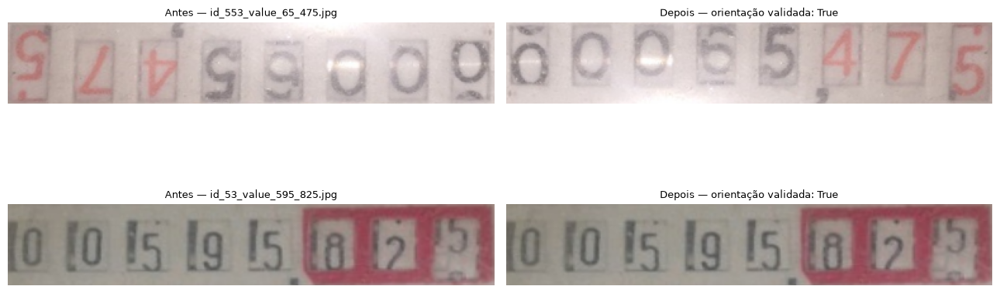

In [84]:
# Parte 3 - Teste das correções de orientação

import matplotlib.pyplot as plt

nomes_teste = [
    "id_553_value_65_475.jpg",
    "id_53_value_595_825.jpg"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 6))

for i, nome in enumerate(nomes_teste):

    # Localiza o registro na base oficial
    linha = base.loc[
        base["photo_name"] == nome
    ].iloc[0]

    # Processa a fotografia
    resultado = processar_imagem(linha)

    faixa_original = resultado["faixa"]

    # Aplica a correção registrada
    faixa_final, validada = aplicar_orientacao_validada(
        faixa_original,
        nome
    )

    # Mostra antes e depois
    axes[i, 0].imshow(faixa_original)
    axes[i, 0].set_title(f"Antes — {nome}", fontsize=9)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(faixa_final)
    axes[i, 1].set_title(
        f"Depois — orientação validada: {validada}",
        fontsize=9
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [85]:
# Parte 3 - Galeria comparativa de orientações

import matplotlib.pyplot as plt
import cv2

def comparar_orientacoes(base_dados, pagina=0, tamanho_lote=6):

    inicio = pagina * tamanho_lote
    fim = inicio + tamanho_lote

    lote = base_dados.iloc[inicio:fim]

    if lote.empty:
        print("Nenhuma imagem nesta página.")
        return

    fig, axes = plt.subplots(
        len(lote),
        2,
        figsize=(14, 2.5 * len(lote)),
        squeeze=False
    )

    for i, (_, linha) in enumerate(lote.iterrows()):

        resultado = processar_imagem(linha)

        faixa_original = resultado["faixa"]

        faixa_180 = cv2.rotate(
            faixa_original,
            cv2.ROTATE_180
        )

        axes[i, 0].imshow(faixa_original)
        axes[i, 0].set_title(
            f"{resultado['photo_name']} — Original",
            fontsize=9
        )
        axes[i, 0].axis("off")

        axes[i, 1].imshow(faixa_180)
        axes[i, 1].set_title(
            f"180° — Rótulo: {resultado['rotulo']}",
            fontsize=9
        )
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

    print("Imagens comparadas:", len(lote))

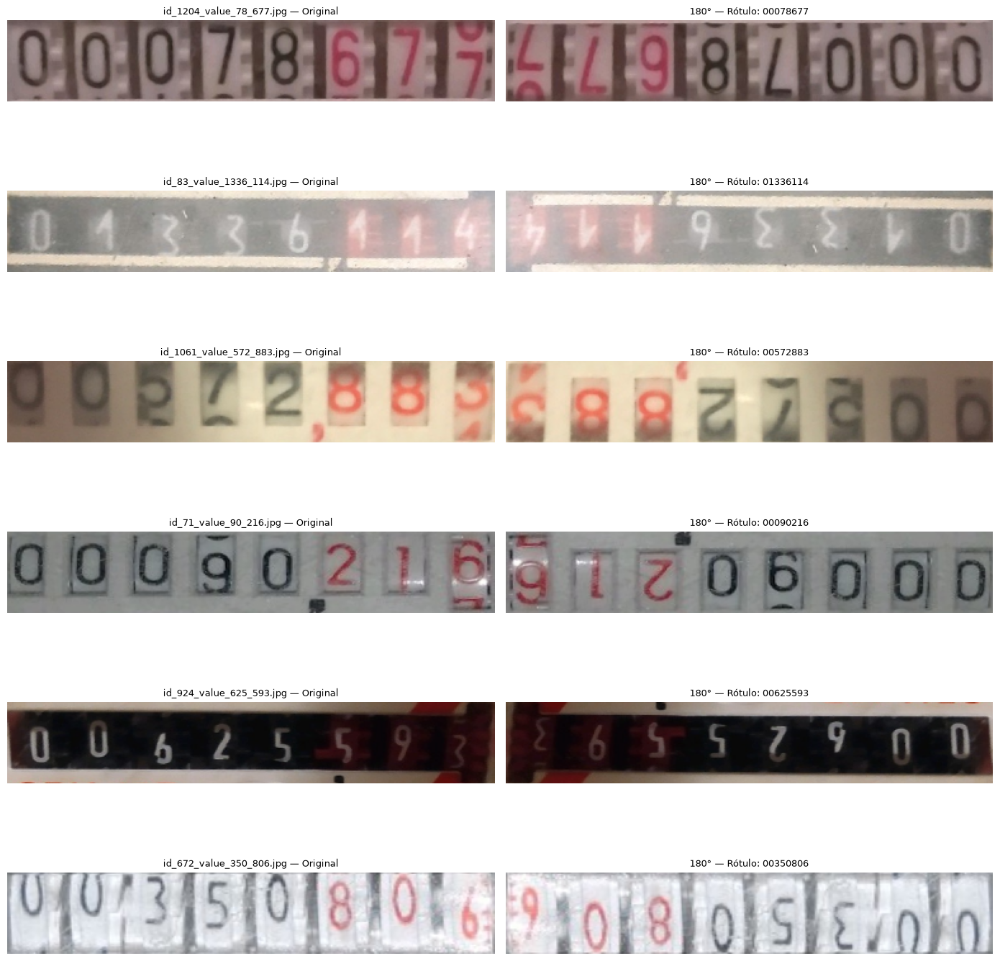

Imagens comparadas: 6


In [86]:
# Seleciona apenas orientações ainda pendentes
controle_pendente = controle[
    ~controle["orientacao_validada"]
]

base_pendente = base[
    base["photo_name"].isin(
        controle_pendente["photo_name"]
    )
].copy()

# Compara as primeiras seis imagens pendentes
comparar_orientacoes(
    base_dados=base_pendente,
    pagina=0,
    tamanho_lote=6
)

In [87]:
# Parte 3 - Registrar orientações verificadas no novo lote

import pandas as pd

caminho_controle = "data/controle/controle_orientacao.csv"

# Recupera o controle salvo
controle_orientacao = pd.read_csv(caminho_controle)

# Fotografias verificadas na última galeria
imagens_corretas_lote = [
    "id_1204_value_78_677.jpg",
    "id_83_value_1336_114.jpg",
    "id_1061_value_572_883.jpg",
    "id_71_value_90_216.jpg",
    "id_924_value_625_593.jpg",
    "id_672_value_350_806.jpg"
]

# Identifica essas fotografias
mascara = controle_orientacao["photo_name"].isin(
    imagens_corretas_lote
)

# Confirma que as seis foram encontradas
assert mascara.sum() == 6

# Registra a orientação validada
controle_orientacao.loc[
    mascara, "orientacao_validada"
] = True

# Nenhuma precisa de rotação
controle_orientacao.loc[
    mascara, "rotacao_necessaria"
] = 0

# Salva o arquivo atualizado
controle_orientacao.to_csv(
    caminho_controle,
    index=False
)

print("Orientações validadas:",
      controle_orientacao["orientacao_validada"].sum())

print("Rotações de 180° registradas:",
      (controle_orientacao["rotacao_necessaria"] == 180).sum())

print("Orientações pendentes:",
      (~controle_orientacao["orientacao_validada"]).sum())

print("Controle atualizado com sucesso!")

Orientações validadas: 19
Rotações de 180° registradas: 8
Orientações pendentes: 1224
Controle atualizado com sucesso!


In [88]:
# Parte 3 - Atualização do controle de orientação

import pandas as pd

# Recupera a versão mais recente do controle
controle = pd.read_csv(
    "data/controle/controle_orientacao.csv"
)

# Identifica as imagens ainda não verificadas
pendentes = controle.loc[
    ~controle["orientacao_validada"]
].copy()

print("Imagens válidas:", len(controle))

print("Orientações verificadas:",
      controle["orientacao_validada"].sum())

print("Orientações pendentes:", len(pendentes))

print("Rotações de 180° registradas:",
      (controle["rotacao_necessaria"] == 180).sum())

Imagens válidas: 1243
Orientações verificadas: 19
Orientações pendentes: 1224
Rotações de 180° registradas: 8


In [89]:
# Parte 3 - Organização das imagens pendentes por orientação geométrica

import pandas as pd

# Recupera as imagens ainda não validadas
pendentes = controle.loc[
    ~controle["orientacao_validada"]
].copy()

# Conta as orientações geométricas
print("IMAGENS PENDENTES POR ORIENTAÇÃO:")

print(
    pendentes["orientacao"].value_counts()
)

# Organiza as imagens verticais primeiro
prioridade = {
    "vertical": 0,
    "horizontal": 1
}

pendentes["prioridade"] = (
    pendentes["orientacao"].map(prioridade)
)

pendentes = pendentes.sort_values(
    ["prioridade", "photo_name"]
).reset_index(drop=True)

print("\nTOTAL DE IMAGENS PENDENTES:")
print(len(pendentes))

print("\nPRIMEIRAS DEZ IMAGENS PRIORIZADAS:")
display(
    pendentes[
        ["photo_name", "orientacao", "n_pontos"]
    ].head(10)
)

IMAGENS PENDENTES POR ORIENTAÇÃO:
orientacao
horizontal    1132
vertical        92
Name: count, dtype: int64

TOTAL DE IMAGENS PENDENTES:
1224

PRIMEIRAS DEZ IMAGENS PRIORIZADAS:


,photo_name,orientacao,n_pontos
0,id_1000_value_176_881.jpg,vertical,6
1,id_1001_value_1113_124.jpg,vertical,6
2,id_1006_value_66_009.jpg,vertical,8
3,id_1013_value_797_523.jpg,vertical,4
4,id_1015_value_1309_052.jpg,vertical,4
5,id_1016_value_367_003.jpg,vertical,4
6,id_1020_value_61_941.jpg,vertical,4
7,id_1038_value_163_397.jpg,vertical,4
8,id_1044_value_44_311.jpg,vertical,4
9,id_1065_value_151_704.jpg,vertical,6


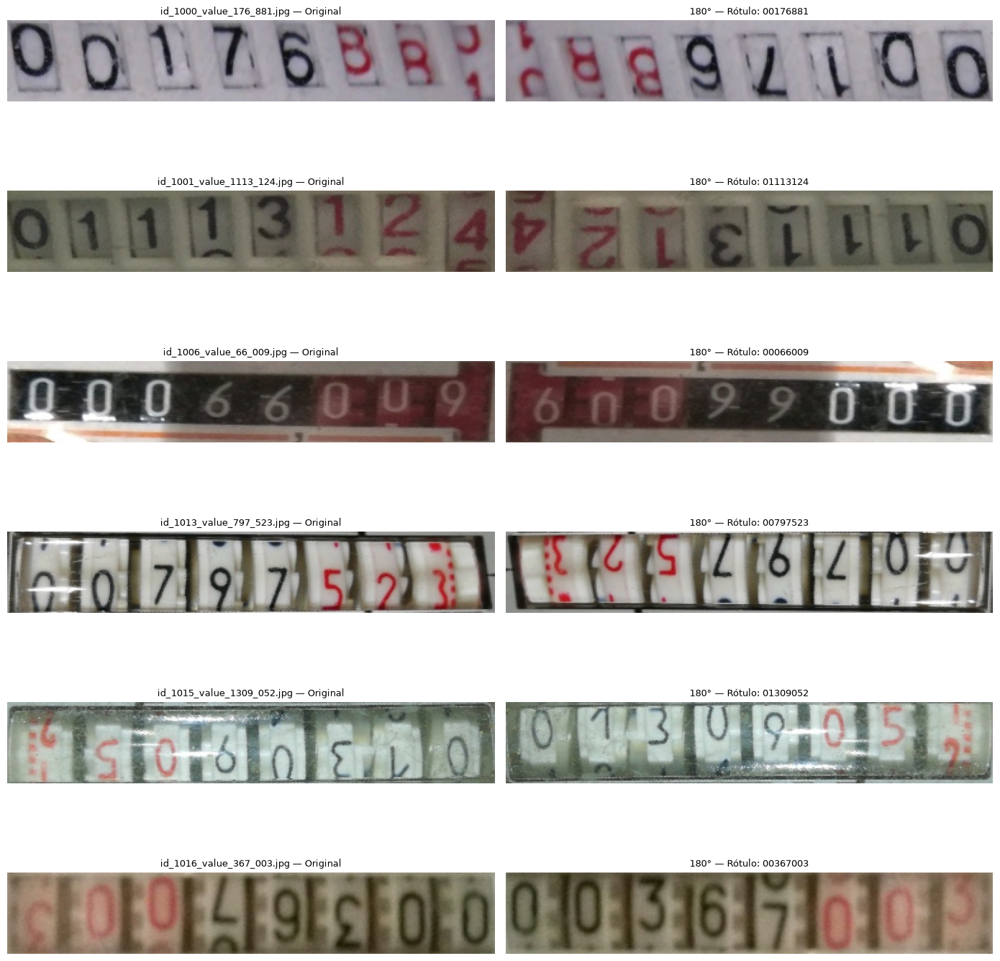

Imagens comparadas: 6


In [90]:
# Parte 3 - Inspeção das primeiras imagens prioritárias

# Seleciona apenas as imagens com orientação vertical
nomes_verticais = pendentes.loc[
    pendentes["orientacao"] == "vertical",
    "photo_name"
]

# Recupera os registros completos da base oficial
base_verticais = base[
    base["photo_name"].isin(nomes_verticais)
].copy()

# Organiza na mesma ordem de prioridade
base_verticais = (
    base_verticais
    .set_index("photo_name")
    .loc[nomes_verticais]
    .reset_index()
)

# Exibe as primeiras seis imagens em duas orientações
comparar_orientacoes(
    base_dados=base_verticais,
    pagina=0,
    tamanho_lote=6
)

In [91]:
# Parte 3 - Registro das orientações do lote prioritário

import pandas as pd

caminho_controle = "data/controle/controle_orientacao.csv"

controle_orientacao = pd.read_csv(caminho_controle)

# Fotografias que já estão na orientação correta
imagens_corretas = [
    "id_1000_value_176_881.jpg",
    "id_1001_value_1113_124.jpg",
    "id_1006_value_66_009.jpg",
    "id_1013_value_797_523.jpg"
]

# Fotografias que precisam de rotação de 180°
imagens_invertidas = [
    "id_1015_value_1309_052.jpg",
    "id_1016_value_367_003.jpg"
]

# Confirma que todos os nomes existem no controle
todos_nomes = imagens_corretas + imagens_invertidas

assert len(todos_nomes) == 6
assert controle_orientacao["photo_name"].isin(todos_nomes).sum() == 6

# Registra as quatro imagens corretas
mascara_corretas = controle_orientacao["photo_name"].isin(
    imagens_corretas
)

controle_orientacao.loc[
    mascara_corretas, "orientacao_validada"
] = True

controle_orientacao.loc[
    mascara_corretas, "rotacao_necessaria"
] = 0

# Registra as duas imagens invertidas
mascara_invertidas = controle_orientacao["photo_name"].isin(
    imagens_invertidas
)

controle_orientacao.loc[
    mascara_invertidas, "orientacao_validada"
] = True

controle_orientacao.loc[
    mascara_invertidas, "rotacao_necessaria"
] = 180

# Salva o controle atualizado
controle_orientacao.to_csv(
    caminho_controle,
    index=False
)

print("Orientações validadas:",
      controle_orientacao["orientacao_validada"].sum())

print("Rotações de 180° registradas:",
      (controle_orientacao["rotacao_necessaria"] == 180).sum())

print("Orientações pendentes:",
      (~controle_orientacao["orientacao_validada"]).sum())

print("Controle atualizado com sucesso!")

Orientações validadas: 25
Rotações de 180° registradas: 10
Orientações pendentes: 1218
Controle atualizado com sucesso!


In [92]:
# Parte 3 - Função para registrar orientações por lote

import pandas as pd
from pathlib import Path

CAMINHO_CONTROLE = Path(
    "data/controle/controle_orientacao.csv"
)

def registrar_orientacoes(corretas, invertidas):

    controle = pd.read_csv(CAMINHO_CONTROLE)

    # Verifica se alguma imagem aparece nas duas listas
    if set(corretas) & set(invertidas):
        raise ValueError(
            "Uma imagem não pode estar nas duas listas."
        )

    nomes = corretas + invertidas

    # Verifica se todos os nomes existem
    desconhecidos = set(nomes) - set(controle["photo_name"])

    if desconhecidos:
        raise ValueError(
            f"Imagens desconhecidas: {desconhecidos}"
        )

    # Registra as imagens já orientadas corretamente
    mascara_corretas = controle["photo_name"].isin(corretas)

    controle.loc[
        mascara_corretas, "orientacao_validada"
    ] = True

    controle.loc[
        mascara_corretas, "rotacao_necessaria"
    ] = 0

    # Registra as imagens que precisam de rotação
    mascara_invertidas = controle["photo_name"].isin(invertidas)

    controle.loc[
        mascara_invertidas, "orientacao_validada"
    ] = True

    controle.loc[
        mascara_invertidas, "rotacao_necessaria"
    ] = 180

    # Salva o arquivo atualizado
    controle.to_csv(CAMINHO_CONTROLE, index=False)

    print("Controle atualizado!")
    print("Orientações validadas:",
          controle["orientacao_validada"].sum())
    print("Rotações de 180°:",
          (controle["rotacao_necessaria"] == 180).sum())
    print("Pendentes:",
          (~controle["orientacao_validada"]).sum())

    return controle


print("Função registrar_orientacoes criada com sucesso!")

Função registrar_orientacoes criada com sucesso!


In [93]:
# Parte 3 - Teste de segurança da função de registro

import pandas as pd

# Recupera o arquivo de controle
controle_teste = pd.read_csv(
    "data/controle/controle_orientacao.csv"
)

# Confere se as colunas necessárias existem
colunas_necessarias = [
    "photo_name",
    "orientacao_validada",
    "rotacao_necessaria"
]

assert all(
    coluna in controle_teste.columns
    for coluna in colunas_necessarias
)

# Confere se cada imagem aparece uma única vez
assert controle_teste["photo_name"].is_unique

# Verifica se as rotações já registradas são válidas
rotacoes = controle_teste.loc[
    controle_teste["orientacao_validada"],
    "rotacao_necessaria"
]

assert rotacoes.isin([0, 180]).all()

print("Verificações concluídas com sucesso!")
print("Total de imagens:", len(controle_teste))
print("Orientações validadas:",
      controle_teste["orientacao_validada"].sum())
print("Orientações pendentes:",
      (~controle_teste["orientacao_validada"]).sum())

Verificações concluídas com sucesso!
Total de imagens: 1243
Orientações validadas: 25
Orientações pendentes: 1218


In [94]:
# Parte 3 - Relatório consolidado da auditoria

import pandas as pd
from pathlib import Path

# Recupera os controles atualizados
controle = pd.read_csv(
    "data/controle/controle_orientacao.csv"
)

geometria = pd.read_csv(
    "data/controle/geometria_visores.csv"
)

investigacao = pd.read_csv(
    "data/controle/investigacao_decimal_zero.csv"
)

# Constrói um relatório por fotografia
auditoria = base[
    ["photo_name", "rotulo_8digitos", "split"]
].copy()

# Incorpora os registros de orientação
auditoria = auditoria.merge(
    controle[
        ["photo_name", "orientacao",
         "orientacao_validada", "rotacao_necessaria"]
    ],
    on="photo_name",
    how="left",
    validate="one_to_one"
)

# Incorpora informações geométricas
auditoria = auditoria.merge(
    geometria[["photo_name", "n_pontos", "proporcao"]],
    on="photo_name",
    how="left",
    validate="one_to_one"
)

# Incorpora observações sobre posições aparentes
auditoria = auditoria.merge(
    investigacao[["photo_name", "situacao"]],
    on="photo_name",
    how="left",
    validate="one_to_one"
)

# Imagens que não foram incluídas na investigação específica
auditoria["situacao"] = auditoria["situacao"].fillna(
    "nao_inspecionada_para_posicoes"
)

# Verificações de integridade
assert len(auditoria) == 1243
assert auditoria["photo_name"].is_unique
assert auditoria["split"].notna().all()
assert auditoria["proporcao"].notna().all()

# Salva o relatório
caminho = Path("data/controle/auditoria_geral.csv")

auditoria.to_csv(caminho, index=False)

print("Relatório consolidado salvo com sucesso!")
print("Total de imagens:", len(auditoria))

print("\nOrientações validadas:")
print(auditoria["orientacao_validada"].sum())

print("\nOrientações pendentes:")
print((~auditoria["orientacao_validada"]).sum())

print("\nSituação das posições aparentes:")
print(auditoria["situacao"].value_counts())

Relatório consolidado salvo com sucesso!
Total de imagens: 1243

Orientações validadas:
25

Orientações pendentes:
1218

Situação das posições aparentes:
situacao
nao_inspecionada_para_posicoes    1207
cinco_posicoes_aparentes            33
oito_posicoes_aparentes              3
Name: count, dtype: int64


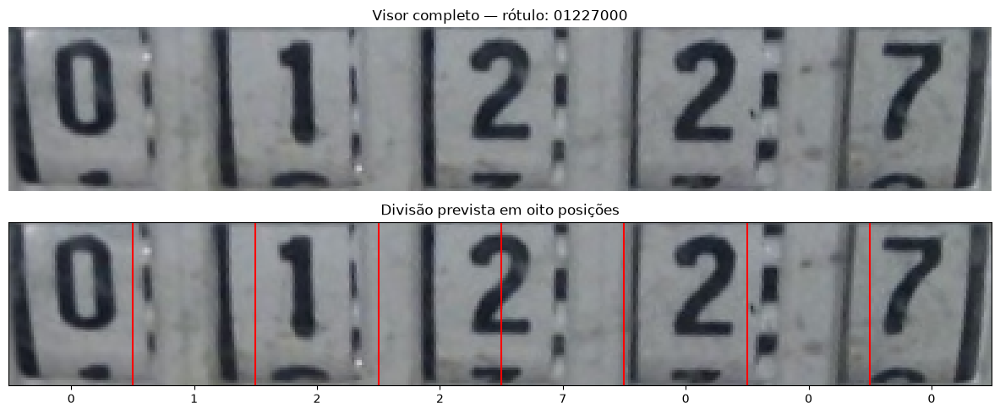

In [95]:
# Parte 3 - Diagnóstico da divisão em oito recortes

import matplotlib.pyplot as plt
import numpy as np

nome = "id_419_value_1227_0.jpg"

linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

resultado = processar_imagem(linha)

faixa, _ = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

rotulo = linha["rotulo_8digitos"]

fig, axes = plt.subplots(2, 1, figsize=(15, 5))

axes[0].imshow(faixa)
axes[0].set_title(f"Visor completo — rótulo: {rotulo}")
axes[0].axis("off")

axes[1].imshow(faixa)

for posicao in range(1, 8):
    axes[1].axvline(posicao * 48, color="red", linewidth=1.5)

axes[1].set_xticks(
    [24 + 48 * i for i in range(8)],
    list(rotulo)
)
axes[1].set_yticks([])
axes[1].set_title("Divisão prevista em oito posições")

plt.tight_layout()
plt.show()

In [96]:
# Etapa 99 - Conferir a anotação original da fotografia

nome = "id_419_value_1227_0.jpg"

registro = df.loc[
    df["photo_name"] == nome,
    ["photo_name", "value", "location"]
]

display(registro)

print("Rótulo normalizado:",
      base.loc[
          base["photo_name"] == nome,
          "rotulo_8digitos"
      ].iloc[0])

,photo_name,value,location
93,id_419_value_1227_0.jpg,1227.0,"{'type': 'polygon', 'data': [{'x': 0.46278, 'y..."


Rótulo normalizado: 01227000


In [97]:
nome = "id_419_value_1227_0.jpg"

registro = df.loc[df["photo_name"] == nome]

print("Fotografia:", registro["photo_name"].iloc[0])
print("Valor original:", registro["value"].iloc[0])
print("Rótulo normalizado:", 
      base.loc[
          base["photo_name"] == nome,
          "rotulo_8digitos"
      ].iloc[0])

print("Quantidade de pontos do polígono:",
      len(eval(registro["location"].iloc[0])))

Fotografia: id_419_value_1227_0.jpg
Valor original: 1227.0
Rótulo normalizado: 01227000
Quantidade de pontos do polígono: 2


In [98]:
import ast

nome = "id_419_value_1227_0.jpg"

localizacao = df.loc[
    df["photo_name"] == nome,
    "location"
].iloc[0]

pontos = (
    ast.literal_eval(localizacao)
    if isinstance(localizacao, str)
    else localizacao
)

print("Tipo da anotação:", type(pontos).__name__)
print("Quantidade de elementos principais:", len(pontos))
print("Conteúdo da anotação:")
print(pontos)

Tipo da anotação: dict
Quantidade de elementos principais: 2
Conteúdo da anotação:
{'type': 'polygon', 'data': [{'x': 0.46278, 'y': 0.27}, {'x': 0.50231, 'y': 0.28554}, {'x': 0.46407, 'y': 0.5697}, {'x': 0.42389, 'y': 0.56184}]}


In [99]:
# Etapa 102 - Verificar os vértices do polígono

vertices = pontos["data"]

print("Tipo da anotação:", pontos["type"])
print("Número de vértices:", len(vertices))

for i, vertice in enumerate(vertices, start=1):
    print(
        f"Vértice {i}: "
        f"x={vertice['x']:.5f}, "
        f"y={vertice['y']:.5f}"
    )

Tipo da anotação: polygon
Número de vértices: 4
Vértice 1: x=0.46278, y=0.27000
Vértice 2: x=0.50231, y=0.28554
Vértice 3: x=0.46407, y=0.56970
Vértice 4: x=0.42389, y=0.56184


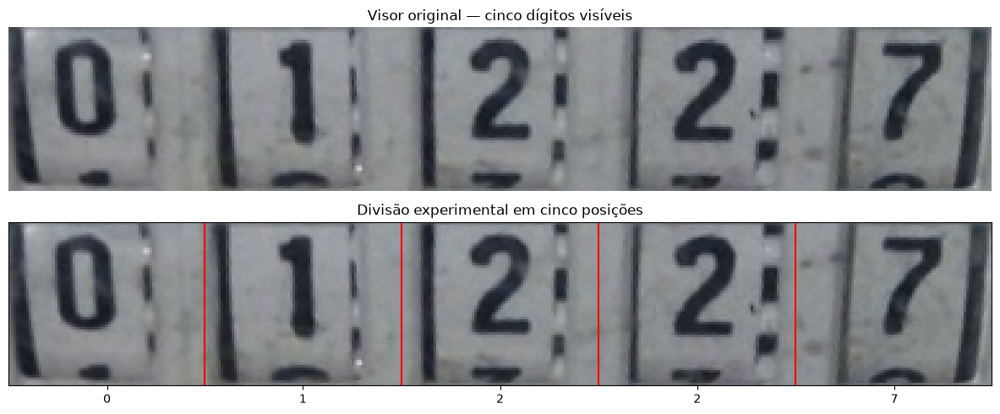

In [100]:
# Etapa 103 - Testar a segmentação de um visor com cinco dígitos

import matplotlib.pyplot as plt
import numpy as np

nome = "id_419_value_1227_0.jpg"

linha = base.loc[base["photo_name"] == nome].iloc[0]

resultado = processar_imagem(linha)

faixa, _ = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

# Divisão experimental em cinco regiões
limites = np.linspace(0, faixa.shape[1], 6).astype(int)

fig, axes = plt.subplots(2, 1, figsize=(14, 5))

axes[0].imshow(faixa)
axes[0].set_title("Visor original — cinco dígitos visíveis")
axes[0].axis("off")

axes[1].imshow(faixa)

for limite in limites[1:-1]:
    axes[1].axvline(
        limite,
        color="red",
        linewidth=1.5
    )

axes[1].set_xticks(
    [(limites[i] + limites[i + 1]) / 2 for i in range(5)],
    list("01227")
)

axes[1].set_yticks([])
axes[1].set_title("Divisão experimental em cinco posições")

plt.tight_layout()
plt.show()

In [102]:
# Etapa 104 - Registrar incompatibilidade de posições

import pandas as pd

caminho = "data/controle/auditoria_geral.csv"

auditoria = pd.read_csv(caminho)

nome = "id_419_value_1227_0.jpg"

# Adiciona campos de auditoria, se ainda não existirem
if "posicoes_visiveis_confirmadas" not in auditoria.columns:
    auditoria["posicoes_visiveis_confirmadas"] = pd.NA

if "observacao_segmentacao" not in auditoria.columns:
    auditoria["observacao_segmentacao"] = pd.NA

mascara = auditoria["photo_name"] == nome

assert mascara.sum() == 1

auditoria.loc[
    mascara, "posicoes_visiveis_confirmadas"
] = 5

auditoria.loc[
    mascara, "observacao_segmentacao"
] = "Cinco digitos visiveis; rotulo normalizado possui oito posicoes"

auditoria.to_csv(caminho, index=False)

print("Registro atualizado:")
display(
    auditoria.loc[
        mascara,
        [
            "photo_name",
            "rotulo_8digitos",
            "posicoes_visiveis_confirmadas",
            "observacao_segmentacao"
        ]
    ]
)

Registro atualizado:


,photo_name,rotulo_8digitos,posicoes_visiveis_confirmadas,observacao_segmentacao
93,id_419_value_1227_0.jpg,1227000,5,Cinco digitos visiveis; rotulo normalizado pos...


In [103]:
# Etapa 105 - Preservar os zeros iniciais dos rótulos

import pandas as pd

caminho = "data/controle/auditoria_geral.csv"

# Lê o rótulo como texto, não como número
auditoria = pd.read_csv(
    caminho,
    dtype={"rotulo_8digitos": "string"}
)

# Restaura as oito posições do rótulo
auditoria["rotulo_8digitos"] = (
    auditoria["rotulo_8digitos"].str.zfill(8)
)

# Confere os rótulos
assert auditoria["rotulo_8digitos"].str.len().eq(8).all()
assert auditoria["rotulo_8digitos"].str.fullmatch(r"\d{8}").all()

# Salva preservando os oito dígitos
auditoria.to_csv(caminho, index=False)

# Verifica o caso que investigamos
registro = auditoria.loc[
    auditoria["photo_name"] == "id_419_value_1227_0.jpg"
]

print("Rótulo corrigido:",
      registro["rotulo_8digitos"].iloc[0])

print("Total de imagens:", len(auditoria))
print("Todos os rótulos possuem oito dígitos:",
      auditoria["rotulo_8digitos"].str.len().eq(8).all())

Rótulo corrigido: 01227000
Total de imagens: 1243
Todos os rótulos possuem oito dígitos: True


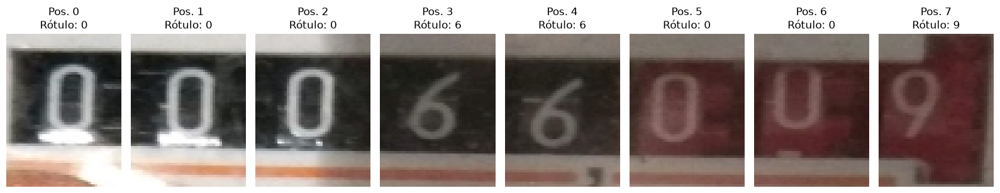

Rótulo: 00066009
Quantidade de recortes: 8
Dimensão de cada recorte: (64, 48, 3)


In [104]:
# Etapa 106 - Testar a extração de oito dígitos

import matplotlib.pyplot as plt

nome = "id_1006_value_66_009.jpg"

linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

resultado = processar_imagem(linha)

faixa, _ = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

rotulo = str(linha["rotulo_8digitos"]).zfill(8)

# Divide a faixa de 384 pixels em oito recortes de 48 pixels
recortes = [
    faixa[:, i * 48:(i + 1) * 48].copy()
    for i in range(8)
]

assert len(recortes) == 8
assert all(recorte.shape == (64, 48, 3) for recorte in recortes)

fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i, ax in enumerate(axes):
    ax.imshow(recortes[i])
    ax.set_title(f"Pos. {i}\nRótulo: {rotulo[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Rótulo:", rotulo)
print("Quantidade de recortes:", len(recortes))
print("Dimensão de cada recorte:", recortes[0].shape)

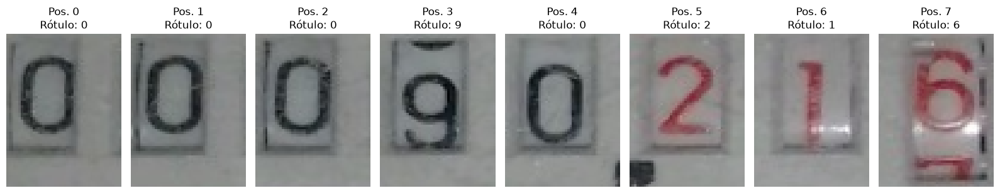

Rótulo esperado: 00090216
Quantidade de recortes: 8


In [105]:
# Etapa 107 - Testar a segmentação em outra fotografia

nome = "id_71_value_90_216.jpg"

linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

resultado = processar_imagem(linha)

faixa, _ = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

rotulo = str(linha["rotulo_8digitos"]).zfill(8)

recortes = [
    faixa[:, i * 48:(i + 1) * 48].copy()
    for i in range(8)
]

fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i, ax in enumerate(axes):
    ax.imshow(recortes[i])
    ax.set_title(f"Pos. {i}\nRótulo: {rotulo[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Rótulo esperado:", rotulo)
print("Quantidade de recortes:", len(recortes))

In [12]:
# Etapa 108 - Função para extrair oito recortes

def extrair_oito_digitos(faixa, rotulo):
    """
    Divide uma faixa de 384x64 pixels em oito recortes
    de 48x64 pixels.

    Não verifica se existem realmente oito dígitos visíveis.
    """

    rotulo = str(rotulo).zfill(8)

    if faixa.shape != (64, 384, 3):
        raise ValueError(
            f"Dimensões inesperadas: {faixa.shape}"
        )

    if len(rotulo) != 8 or not rotulo.isdigit():
        raise ValueError("O rótulo deve conter oito dígitos.")

    recortes = []

    for posicao in range(8):
        inicio = posicao * 48
        fim = inicio + 48

        recorte = faixa[:, inicio:fim].copy()

        recortes.append({
            "posicao": posicao,
            "digito": int(rotulo[posicao]),
            "imagem": recorte
        })

    return recortes


print("Função extrair_oito_digitos criada com sucesso!")

Função extrair_oito_digitos criada com sucesso!


In [107]:
# Etapa 109 - Testar a função extrair_oito_digitos

nome = "id_1006_value_66_009.jpg"

# Recupera o registro da fotografia
linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

# Processa e retifica o visor
resultado = processar_imagem(linha)

# Aplica a orientação previamente validada
faixa, _ = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

# Recupera o rótulo como texto
rotulo = str(linha["rotulo_8digitos"]).zfill(8)

# Extrai os oito recortes
recortes_teste = extrair_oito_digitos(faixa, rotulo)

# Verificações
assert len(recortes_teste) == 8

assert all(
    item["imagem"].shape == (64, 48, 3)
    for item in recortes_teste
)

assert "".join(
    str(item["digito"]) for item in recortes_teste
) == rotulo

print("Teste concluído com sucesso!")
print("Fotografia:", nome)
print("Rótulo:", rotulo)
print("Quantidade de recortes:", len(recortes_teste))
print("Dimensão do primeiro recorte:",
      recortes_teste[0]["imagem"].shape)

Teste concluído com sucesso!
Fotografia: id_1006_value_66_009.jpg
Rótulo: 00066009
Quantidade de recortes: 8
Dimensão do primeiro recorte: (64, 48, 3)


In [108]:
# Etapa 110 - Salvar os primeiros oito recortes

from pathlib import Path
import cv2
import pandas as pd

nome = "id_1006_value_66_009.jpg"

linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

# Utiliza as funções que já construímos
resultado = processar_imagem(linha)

faixa, orientacao_aplicada = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

rotulo = str(linha["rotulo_8digitos"]).zfill(8)
split = linha["split"]

recortes = extrair_oito_digitos(faixa, rotulo)

# Identificador extraído do nome original
image_id = nome.split("_value_")[0]

registros = []

for item in recortes:
    posicao = item["posicao"]
    digito = item["digito"]
    imagem = item["imagem"]

    pasta = Path("digits") / split / str(digito)
    pasta.mkdir(parents=True, exist_ok=True)

    caminho = pasta / f"{image_id}_{posicao}.png"

    # OpenCV espera BGR; nossas imagens estão em RGB
    imagem_bgr = cv2.cvtColor(
        imagem,
        cv2.COLOR_RGB2BGR
    )

    sucesso = cv2.imwrite(str(caminho), imagem_bgr)

    if not sucesso:
        raise RuntimeError(f"Erro ao salvar {caminho}")

    registros.append({
        "image_id": image_id,
        "photo_name": nome,
        "position": posicao,
        "digit": digito,
        "split": split,
        "crop_path": caminho.as_posix()
    })

indice_teste = pd.DataFrame(registros)

print("Recortes salvos:", len(indice_teste))
print("Split:", split)
print("Rotação aplicada:", orientacao_aplicada)

display(indice_teste)

Recortes salvos: 8
Split: train
Rotação aplicada: True


,image_id,photo_name,position,digit,split,crop_path
0,id_1006,id_1006_value_66_009.jpg,0,0,train,digits/train/0/id_1006_0.png
1,id_1006,id_1006_value_66_009.jpg,1,0,train,digits/train/0/id_1006_1.png
2,id_1006,id_1006_value_66_009.jpg,2,0,train,digits/train/0/id_1006_2.png
3,id_1006,id_1006_value_66_009.jpg,3,6,train,digits/train/6/id_1006_3.png
4,id_1006,id_1006_value_66_009.jpg,4,6,train,digits/train/6/id_1006_4.png
5,id_1006,id_1006_value_66_009.jpg,5,0,train,digits/train/0/id_1006_5.png
6,id_1006,id_1006_value_66_009.jpg,6,0,train,digits/train/0/id_1006_6.png
7,id_1006,id_1006_value_66_009.jpg,7,9,train,digits/train/9/id_1006_7.png


In [109]:
# Etapa 111 - Verificar os recortes salvos

from pathlib import Path
import cv2

for _, registro in indice_teste.iterrows():
    caminho = Path(registro["crop_path"])

    assert caminho.exists(), f"Arquivo não encontrado: {caminho}"

    imagem = cv2.imread(str(caminho))

    assert imagem is not None, f"Erro ao ler: {caminho}"
    assert imagem.shape == (64, 48, 3), (
        f"Dimensão incorreta: {caminho}"
    )

print("Verificação concluída com sucesso!")
print("Arquivos encontrados:", len(indice_teste))
print("Todos os recortes possuem dimensões 64 x 48.")

Verificação concluída com sucesso!
Arquivos encontrados: 8
Todos os recortes possuem dimensões 64 x 48.


In [110]:
# Etapa 112 - Criar o índice inicial

from pathlib import Path
import pandas as pd

caminho_indice = Path("digits/index.csv")

colunas_indice = [
    "image_id",
    "photo_name",
    "position",
    "digit",
    "split",
    "crop_path"
]

indice = indice_teste[colunas_indice].copy()

# Verificar duplicações
assert not indice.duplicated(
    subset=["photo_name", "position"]
).any()

# Verificar se os arquivos existem
for caminho in indice["crop_path"]:
    assert Path(caminho).is_file()

# Salvar o índice
indice.to_csv(caminho_indice, index=False)

# Conferir o resultado
indice_verificado = pd.read_csv(caminho_indice)

print("Índice criado com sucesso!")
print("Caminho:", caminho_indice)
print("Total de recortes:", len(indice_verificado))
print(
    "Fotografias representadas:",
    indice_verificado["photo_name"].nunique()
)

display(indice_verificado.head())

Índice criado com sucesso!
Caminho: digits\index.csv
Total de recortes: 8
Fotografias representadas: 1


,image_id,photo_name,position,digit,split,crop_path
0,id_1006,id_1006_value_66_009.jpg,0,0,train,digits/train/0/id_1006_0.png
1,id_1006,id_1006_value_66_009.jpg,1,0,train,digits/train/0/id_1006_1.png
2,id_1006,id_1006_value_66_009.jpg,2,0,train,digits/train/0/id_1006_2.png
3,id_1006,id_1006_value_66_009.jpg,3,6,train,digits/train/6/id_1006_3.png
4,id_1006,id_1006_value_66_009.jpg,4,6,train,digits/train/6/id_1006_4.png


In [1]:
# Etapa 115 - Verificar o estado do notebook

variaveis = [
    "base",
    "processar_imagem",
    "aplicar_orientacao_validada",
    "extrair_oito_digitos",
    "indice_teste"
]

for nome in variaveis:
    existe = nome in globals()
    print(f"{nome}: {'OK' if existe else 'PRECISA RECARREGAR'}")

base: PRECISA RECARREGAR
processar_imagem: PRECISA RECARREGAR
aplicar_orientacao_validada: PRECISA RECARREGAR
extrair_oito_digitos: PRECISA RECARREGAR
indice_teste: PRECISA RECARREGAR


In [13]:
# Etapa 129 - Verificar o ambiente recuperado

elementos = [
    "df",
    "splits",
    "df_rotulos",
    "base",
    "extrair_rotulo",
    "retificar_visor",
    "processar_imagem",
    "controle",
    "aplicar_orientacao_validada",
    "extrair_oito_digitos"
]

for nome in elementos:
    disponivel = nome in globals()
    print(f"{nome}: {'OK' if disponivel else 'AUSENTE'}")

df: OK
splits: OK
df_rotulos: OK
base: OK
extrair_rotulo: OK
retificar_visor: OK
processar_imagem: OK
controle: OK
aplicar_orientacao_validada: OK
extrair_oito_digitos: OK


In [14]:
# Etapa 130 - Teste completo do processamento

nome = "id_1006_value_66_009.jpg"

# Localiza a fotografia
linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

# Retifica o visor
resultado = processar_imagem(linha)

# Aplica a orientação validada
faixa, orientacao_validada = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

# Extrai os oito recortes
rotulo = str(linha["rotulo_8digitos"]).zfill(8)

recortes = extrair_oito_digitos(faixa, rotulo)

# Verificações
assert orientacao_validada is True
assert len(recortes) == 8
assert all(
    item["imagem"].shape == (64, 48, 3)
    for item in recortes
)

print("Processamento completo funcionando!")
print("Fotografia:", nome)
print("Orientação validada:", orientacao_validada)
print("Rótulo:", rotulo)
print("Recortes produzidos:", len(recortes))

Processamento completo funcionando!
Fotografia: id_1006_value_66_009.jpg
Orientação validada: True
Rótulo: 00066009
Recortes produzidos: 8


In [15]:
# Etapa 131 - Selecionar fotografias para segmentação

import pandas as pd

# Recupera a auditoria salva
auditoria = pd.read_csv(
    "data/controle/auditoria_geral.csv",
    dtype={"rotulo_8digitos": "string"}
)

# Fotografias com orientação já verificada
orientadas = auditoria.loc[
    auditoria["orientacao_validada"] == True
].copy()

# Exclui temporariamente os casos identificados
# como tendo cinco posições aparentes
candidatas = orientadas.loc[
    orientadas["situacao"] != "cinco_posicoes_aparentes"
].copy()

print("Total de fotografias:", len(auditoria))
print("Orientações verificadas:", len(orientadas))
print("Candidatas à inspeção de segmentação:", len(candidatas))

print("\nPrimeiras fotografias candidatas:")
display(
    candidatas[
        ["photo_name", "rotulo_8digitos", "split", "situacao"]
    ].head(10)
)

Total de fotografias: 1243
Orientações verificadas: 25
Candidatas à inspeção de segmentação: 23

Primeiras fotografias candidatas:


,photo_name,rotulo_8digitos,split,situacao
0,id_53_value_595_825.jpg,00595825,train,nao_inspecionada_para_posicoes
1,id_553_value_65_475.jpg,00065475,train,nao_inspecionada_para_posicoes
2,id_407_value_21_86.jpg,00021860,test,nao_inspecionada_para_posicoes
3,id_252_value_313_322.jpg,00313322,train,nao_inspecionada_para_posicoes
4,id_851_value_305_162.jpg,00305162,train,nao_inspecionada_para_posicoes
5,id_398_value_8_898.jpg,00008898,train,nao_inspecionada_para_posicoes
6,id_1204_value_78_677.jpg,00078677,train,nao_inspecionada_para_posicoes
7,id_83_value_1336_114.jpg,01336114,test,nao_inspecionada_para_posicoes
8,id_1061_value_572_883.jpg,00572883,train,nao_inspecionada_para_posicoes
9,id_71_value_90_216.jpg,00090216,train,nao_inspecionada_para_posicoes


In [16]:
# Etapa 132 - Conferir fotografias com segmentação inspecionada

nomes_verificados = [
    "id_1006_value_66_009.jpg",
    "id_71_value_90_216.jpg"
]

verificadas = candidatas.loc[
    candidatas["photo_name"].isin(nomes_verificados)
].copy()

print("Fotografias encontradas:", len(verificadas))

display(
    verificadas[
        ["photo_name", "rotulo_8digitos", "split"]
    ]
)

Fotografias encontradas: 2


,photo_name,rotulo_8digitos,split
9,id_71_value_90_216.jpg,00090216,train
441,id_1006_value_66_009.jpg,00066009,train


In [17]:
# Etapa 133 - Salvar a segunda fotografia no dataset

from pathlib import Path
import pandas as pd
import cv2

nome = "id_71_value_90_216.jpg"

caminho_indice = Path("digits/index.csv")
indice = pd.read_csv(caminho_indice)

# Impede duplicação de fotografias
assert nome not in indice["photo_name"].values, (
    "Esta fotografia já está registrada no índice."
)

# Recupera o registro original
linha = base.loc[
    base["photo_name"] == nome
].iloc[0]

# Processa a fotografia
resultado = processar_imagem(linha)

faixa, validada = aplicar_orientacao_validada(
    resultado["faixa"], nome
)

assert validada, "Orientação ainda não validada."

rotulo = str(linha["rotulo_8digitos"]).zfill(8)
split = linha["split"]
image_id = nome.split("_value_")[0]

# Extrai os oito dígitos
recortes = extrair_oito_digitos(faixa, rotulo)

novos_registros = []

for item in recortes:
    posicao = item["posicao"]
    digito = item["digito"]

    pasta = Path("digits") / split / str(digito)
    pasta.mkdir(parents=True, exist_ok=True)

    caminho = pasta / f"{image_id}_{posicao}.png"

    # Não sobrescreve arquivos existentes
    assert not caminho.exists(), (
        f"Arquivo já existente: {caminho}"
    )

    imagem_bgr = cv2.cvtColor(
        item["imagem"],
        cv2.COLOR_RGB2BGR
    )

    sucesso = cv2.imwrite(str(caminho), imagem_bgr)

    assert sucesso, f"Falha ao salvar: {caminho}"

    novos_registros.append({
        "image_id": image_id,
        "photo_name": nome,
        "position": posicao,
        "digit": digito,
        "split": split,
        "crop_path": caminho.as_posix()
    })

# Atualiza o índice
indice = pd.concat(
    [indice, pd.DataFrame(novos_registros)],
    ignore_index=True
)

# Verifica duplicações
assert not indice.duplicated(
    subset=["photo_name", "position"]
).any()

indice.to_csv(caminho_indice, index=False)

print("Recortes adicionados:", len(novos_registros))
print("Total de recortes no índice:", len(indice))
print("Fotografias representadas:",
      indice["photo_name"].nunique())

Recortes adicionados: 8
Total de recortes no índice: 16
Fotografias representadas: 2


In [18]:
# Geração automatizada dos recortes e índice

from pathlib import Path
import pandas as pd
import cv2

registros = []
problemas = []

for numero, (_, linha) in enumerate(base.iterrows(), start=1):
    nome = linha["photo_name"]

    try:
        resultado = processar_imagem(linha)
        faixa, validada = aplicar_orientacao_validada(
            resultado["faixa"], nome
        )

        rotulo = str(linha["rotulo_8digitos"]).zfill(8)
        recortes = extrair_oito_digitos(faixa, rotulo)

        if not validada:
            problemas.append({
                "photo_name": nome,
                "problema": "orientacao_nao_validada"
            })

        for item in recortes:
            posicao = item["posicao"]
            digito = item["digito"]
            split = linha["split"]
            image_id = nome.split("_value_")[0]

            pasta = Path("digits") / split / str(digito)
            pasta.mkdir(parents=True, exist_ok=True)

            caminho = pasta / f"{image_id}_{posicao}.png"

            if not caminho.exists():
                imagem_bgr = cv2.cvtColor(
                    item["imagem"], cv2.COLOR_RGB2BGR
                )
                if not cv2.imwrite(str(caminho), imagem_bgr):
                    raise RuntimeError(f"Falha ao salvar {caminho}")

            registros.append({
                "image_id": image_id,
                "photo_name": nome,
                "position": posicao,
                "digit": digito,
                "split": split,
                "crop_path": caminho.as_posix()
            })

    except Exception as erro:
        problemas.append({
            "photo_name": nome,
            "problema": str(erro)
        })

    if numero % 100 == 0:
        print(f"Processadas: {numero}/{len(base)}")

indice = pd.DataFrame(registros)
indice.to_csv("digits/index.csv", index=False)

pd.DataFrame(problemas).to_csv(
    "data/controle/problemas_processamento.csv",
    index=False
)

print("\nFotografias no índice:", indice["photo_name"].nunique())
print("Recortes no índice:", len(indice))
print("Ocorrências registradas:", len(problemas))

Processadas: 100/1243
Processadas: 200/1243
Processadas: 300/1243
Processadas: 400/1243
Processadas: 500/1243
Processadas: 600/1243
Processadas: 700/1243
Processadas: 800/1243
Processadas: 900/1243
Processadas: 1000/1243
Processadas: 1100/1243
Processadas: 1200/1243

Fotografias no índice: 1243
Recortes no índice: 9944
Ocorrências registradas: 1218
